# AI-Powered Customer Voice Intelligence and Business Decision Platform
**Project MSDS-MAJOR-CVI-001 | Client: InsightRetail India (anonymised) | MSDS Major Project**

This notebook follows the 12 workbook activities. It **recomputes the quick parts live** (data-quality rules, fault injection, SQL KPIs, hypothesis tests, pre-processing, model scoring) and **loads the saved outputs** of the full pipeline (`python run_pipeline.py`) for the heavier steps (cross-validation, mining, bootstrap). Figures are the project's validated visual system (`outputs/figures`).

**Read first - three data facts that shape every result:** (1) the feedback text is 100% templated, so model scores of 100% are a ceiling effect; (2) `Reference_Sentiment` is a deterministic function of `Rating`; (3) `Customer_ID` is not a stable key, so every customer metric is at feedback-record level.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, json, sqlite3
from pathlib import Path
for _p in [Path.cwd(), *Path.cwd().parents]:          # find the project's src/ so the notebook runs without `pip install -e .`
    if (_p / "src" / "cvi").is_dir():
        sys.path.insert(0, str(_p / "src")); break
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from scipy import stats
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
from cvi import config as C, ingest, quality, transform, kpis as K, warehouse as W, nlp_prep, sentiment, topics
from cvi.utils import load_metrics
print("python", sys.version.split()[0], "| seed", C.SEED, "| project root:", C.ROOT.name)
def fig(name, width=860): display(Image(filename=str(C.FIG_DIR / f"{name}.png"), width=width))
def table(name): return pd.read_csv(C.TABLE_DIR / f"{name}.csv")
M = {k: load_metrics(k) for k in ["ingest", "transform", "eda", "sentiment", "topics", "mining", "integrate", "decision", "validate"]}

python 3.13.9 | seed 42 | project root: Major Project


## Activity 1 - Problem framing and success metrics
Five analytical questions: (1) how much feedback is negative and does it vary by segment; (2) which themes dominate and carry risk; (3) how sentiment links to repeat purchase, CSAT, resolution time and revenue; (4) which segments are high-risk or high-opportunity; (5) how much revenue is at risk and which actions come first. KPI definitions follow the supplied *Metric Guidance*; targets are **proposed assumptions** (none were supplied).

,kpi,current,proposed_target,status_label,definition_source
0,Negative Sentiment Rate,0.2404,0.2,Off target,Metric Guidance
1,Repeat Purchase Rate,0.5746,0.6,Near target,Metric Guidance
2,Average Resolution Time (h),11.2562,10.0,Off target,Metric Guidance
3,Revenue at Risk (share of revenue),0.2448,0.2,Off target,Metric Guidance
4,Net Sentiment Score (pts),33.0417,40.0,Off target,Derived
5,Average CSAT (1-5),3.4619,3.7,Near target,Derived
6,"Resolution time, negative cases (h)",18.1139,12.0,Well off target,Derived
7,"Repeat rate, negative-sentiment customers",0.2825,0.4,Well off target,Derived


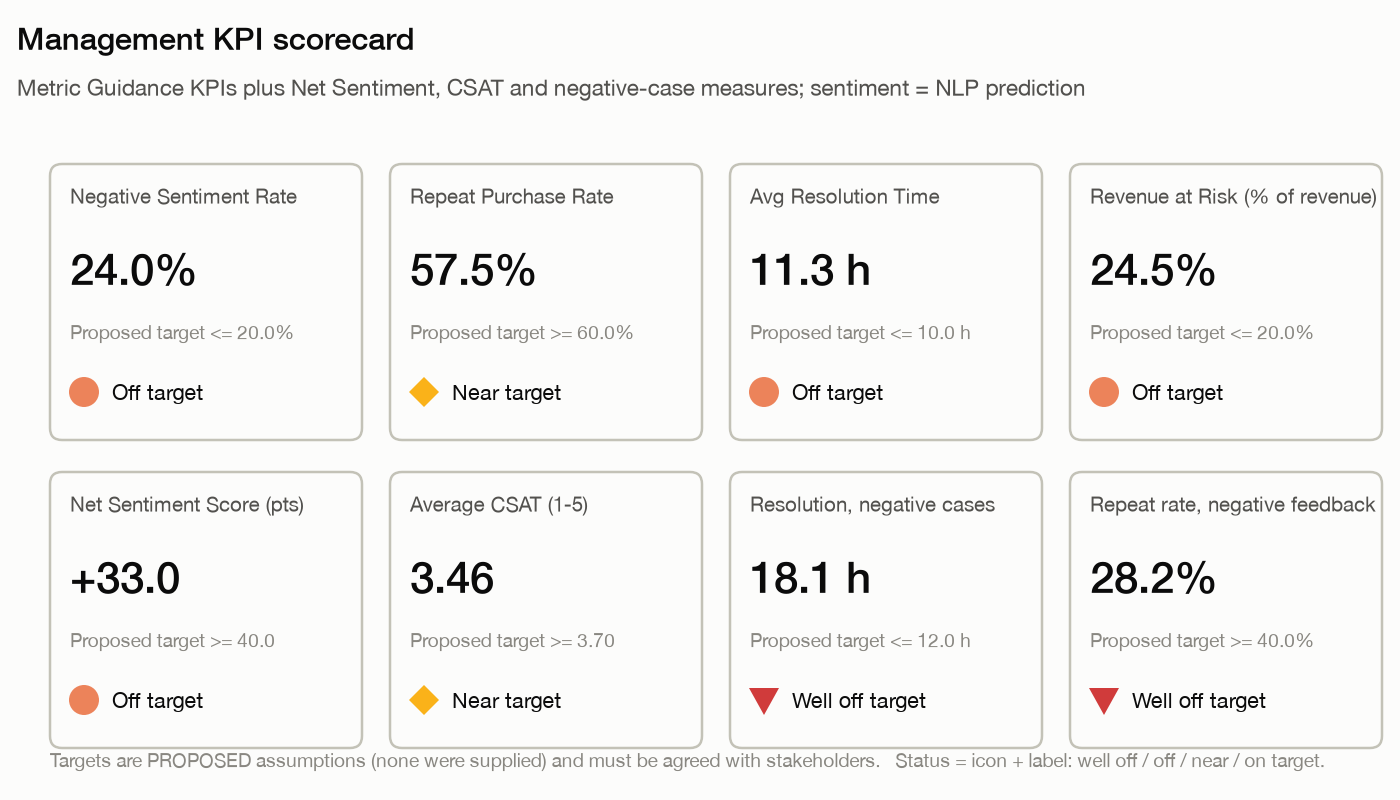

In [2]:
sc = table("decision_kpi_scorecard")
display(sc[["kpi", "current", "proposed_target", "status_label", "definition_source"]].round(4))
fig("fig27_kpi_scorecard", 820)

## Activity 2 - Data engineering and ingestion
Bronze / Silver / Gold pipeline; one command (`python run_pipeline.py`) runs all 12 stages in about two minutes.

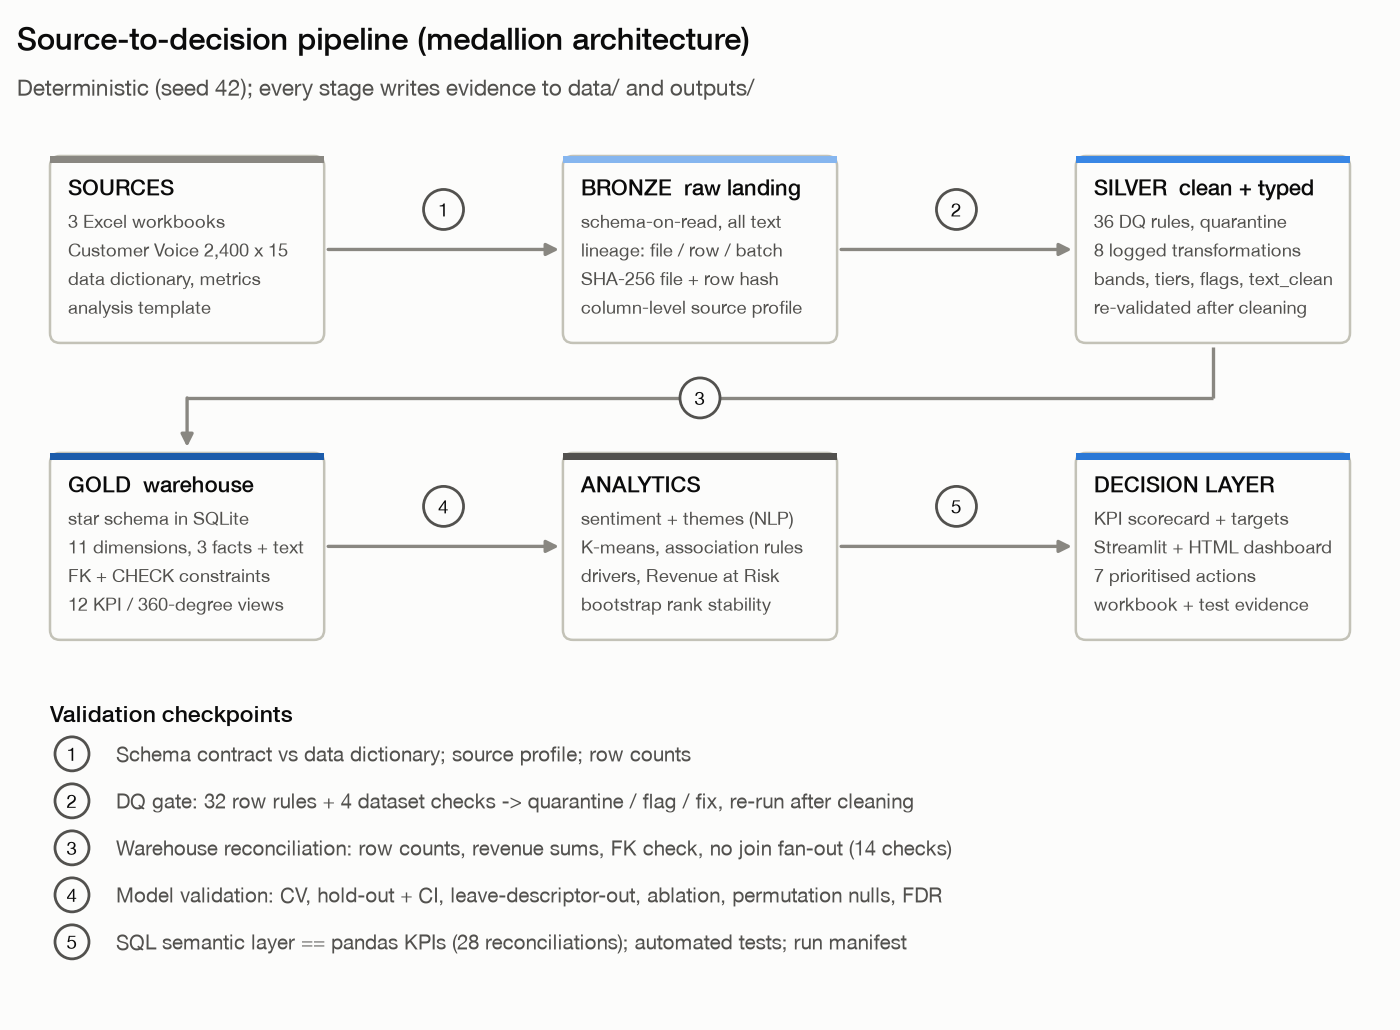

source: (2400, 15) | schema drift: {'missing_columns': [], 'unexpected_columns': [], 'order_matches': True, 'n_columns': 15}


,column,dictionary_type,non_null,null_count,distinct,min,max,pattern_conformance_pct
0,Feedback_ID,Identifier,2400,0,2400,FB-00001,FB-02400,100.0
1,Customer_ID,Identifier,2400,0,1114,C-00001,C-01350,100.0
2,Region,Categorical,2400,0,5,Central,West,NaN
3,Channel,Categorical,2400,0,4,App,Web,NaN
4,Product_Category,Categorical,2400,0,5,Beauty,Home,NaN
5,Issue_Category,Categorical,2400,0,8,App Experience,Refund Delay,NaN
6,Rating,Numeric,2400,0,5,1.0,5.0,NaN
7,Feedback_Text,Text,2400,0,1590,The app experience experience was acceptable. I used the app channel for my home order...,The refund delay experience was unhelpful. I used the web channel for my grocery order...,NaN
8,Reference_Sentiment,Categorical,2400,0,3,Negative,Positive,NaN
9,Customer_Revenue_INR,Numeric,2400,0,2397,503.5,11998.92,NaN


In [3]:
fig("fig01_pipeline_architecture", 820)
raw = ingest.read_source()
print("source:", raw.shape, "| schema drift:", ingest.schema_drift(raw))
prof = ingest.profile_source(raw)
display(prof[["column", "dictionary_type", "non_null", "null_count", "distinct", "min", "max", "pattern_conformance_pct"]])

## Activity 3 - Data quality and feature preparation
The 36 rules are executed live on the raw data, then **fault injection** proves the pipeline catches problems that the (clean) supplied data does not contain.

In [4]:
bronze = ingest.load_bronze()
rep = quality.run_rules(bronze[C.EXPECTED_COLUMNS])
print("score:", {k: v for k, v in rep["score"].items() if k != "dimension_pass_rate_pct"})
display(rep["report"][rep["report"].rows_failed > 0][["rule_id", "dimension", "severity", "description", "rows_failed", "pct_failed", "status"]])

score: {'rows': 2400, 'rows_failing_error_rules': 0, 'pct_rows_passing_all_error_rules': 100.0, 'rows_with_any_warning': 397, 'pct_rows_fully_clean': 83.458, 'n_rules': 36, 'n_rules_pass': 28, 'n_rules_fail': 0, 'n_rules_warn': 5, 'n_rules_info': 3}


,rule_id,dimension,severity,description,rows_failed,pct_failed,status
6,DQ-U03,Uniqueness,info,Same customer + identical text (informational: templated text repeats legitimately),1,0.042,INFO
27,DQ-K04,Consistency,warn,Repeat_Purchase_Flag=1 requires Order_Count>=2 (logical consistency),113,4.708,WARN
28,DQ-K05,Consistency,warn,Text has no repeated adjacent word (e.g. 'experience experience'),298,12.417,WARN
30,DQ-P02,Plausibility,info,Resolution_Time_Hours has no mild outliers (1.5xIQR fence),12,0.500,INFO
31,DQ-P03,Plausibility,info,Resolution_Time_Hours is not censored at a floor of 1.0h,109,4.542,INFO
33,DQ-E01,Entity integrity,warn,Region is stable across a customer's records (entity-resolution risk if not),647,89.488,WARN
34,DQ-E02,Entity integrity,warn,Customer_Revenue_INR is stable across a customer's records (entity-resolution risk if ...,723,100.000,WARN
35,DQ-X01,Text realism,warn,Feedback_Text is free-form (not >95% one fixed sentence template),2400,100.000,WARN


kept 57 | quarantined 3


,Feedback_ID,dq_error_reason
1,FB-00002,DQ-V03-Region
3,FB-00004,DQ-V04
6,FB-00001,DQ-U01


,region,customer_revenue_inr,channel,dq_flags
feedback_id,,,,
FB-00003,North,8510.43,Marketplace,DQ-K04;DQ-V11
FB-00005,West,NaN,Store,DQ-C03
FB-00006,East,4327.59,Unknown,DQ-C02;DQ-K03


,step,description,rows_in,rows_out,cells_changed
0,TR-01,"NFKC-normalise, trim, collapse whitespace on all string fields",2400,2400,0
1,TR-02,Map categoricals to canonical casing; blank -> 'Unknown',2400,2400,0
2,TR-03,"Coerce numeric fields (unparseable -> NaN, no imputation of outcome measures)",2400,2400,0
3,TR-04,Quarantine rows failing error rules / duplicates (keep first occurrence),2400,2400,0
4,TR-05,Collapse repeated adjacent words in text_clean (template glitch 'experience experience'),2400,2400,298
5,TR-07,Derive text features: character and word counts,2400,2400,0
6,TR-06,"Derive resolution/SLA bands, revenue tiers, order bands, AOV, theme/channel/source cla...",2400,2400,0
7,TR-08,"Strict typing, deterministic ordering by feedback_id, lineage retained",2400,2400,0


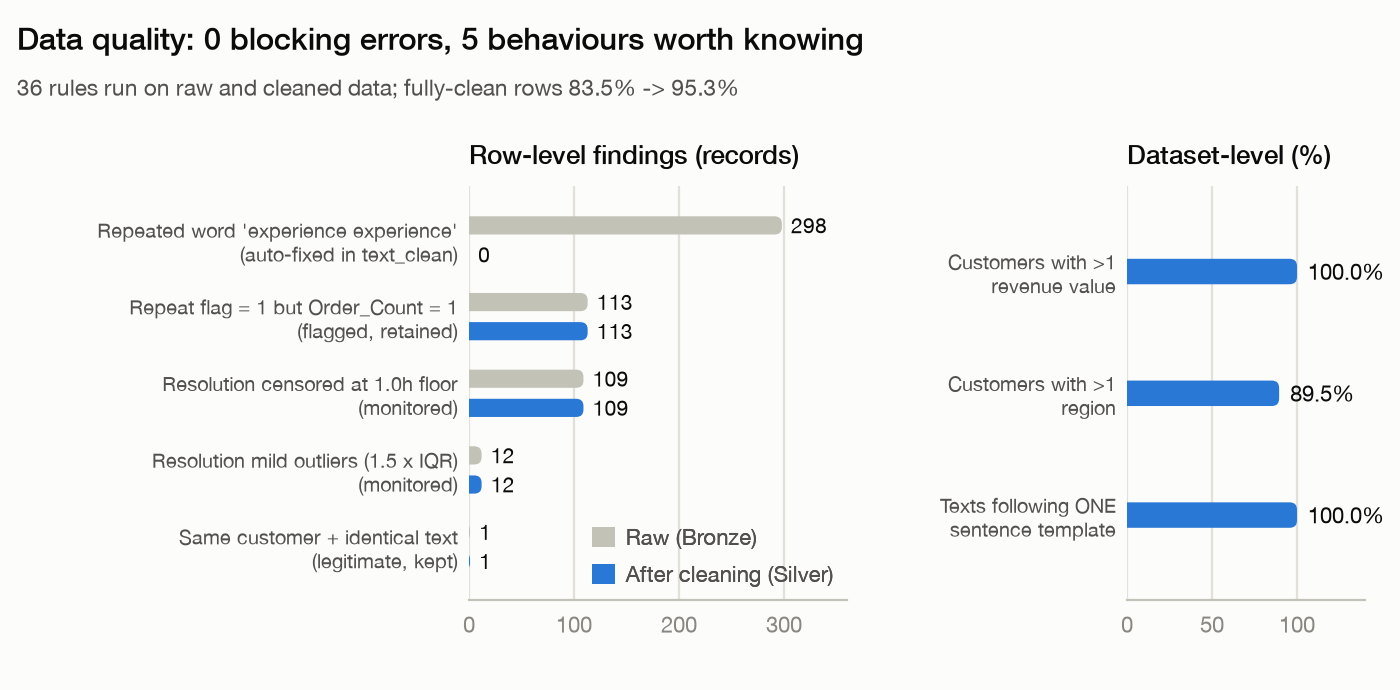

In [5]:
# Fault injection on a 60-row sample: each fault must be caught and handled as specified
s = bronze.head(60).copy().reset_index(drop=True)
s.loc[1, "Region"] = "Mars"                      # invalid category      -> quarantine (DQ-V03)
s.loc[2, "Region"] = "north"                     # case variant          -> canonicalised to 'North'
s.loc[3, "Rating"] = "7"                         # impossible value      -> quarantine (DQ-V04)
s.loc[4, "Customer_Revenue_INR"] = pd.NA         # missing outcome       -> kept as NaN, never imputed (DQ-C03)
s.loc[5, "Channel"] = ""                         # blank categorical     -> 'Unknown' + flagged (DQ-C02)
s.loc[6, "Feedback_ID"] = s.loc[0, "Feedback_ID"]# duplicate ID          -> quarantine (DQ-U01)
out = transform.clean(s)
print("kept", len(out["silver"]), "| quarantined", len(out["quarantine"]))
display(out["quarantine"][["Feedback_ID", "dq_error_reason"]])
display(out["silver"].set_index("feedback_id").loc[[s.loc[2, "Feedback_ID"], s.loc[4, "Feedback_ID"], s.loc[5, "Feedback_ID"]], ["region", "customer_revenue_inr", "channel", "dq_flags"]])
display(pd.read_csv(C.DQ_DIR / "transformation_log.csv"))
fig("fig04_dq_findings", 820)

## Activity 4 - Warehouse and analytical model
Star schema at feedback grain (Customer_ID is a weak key). The KPI views in SQL are the semantic layer; they reconcile with the pandas KPI functions (28 of 28).

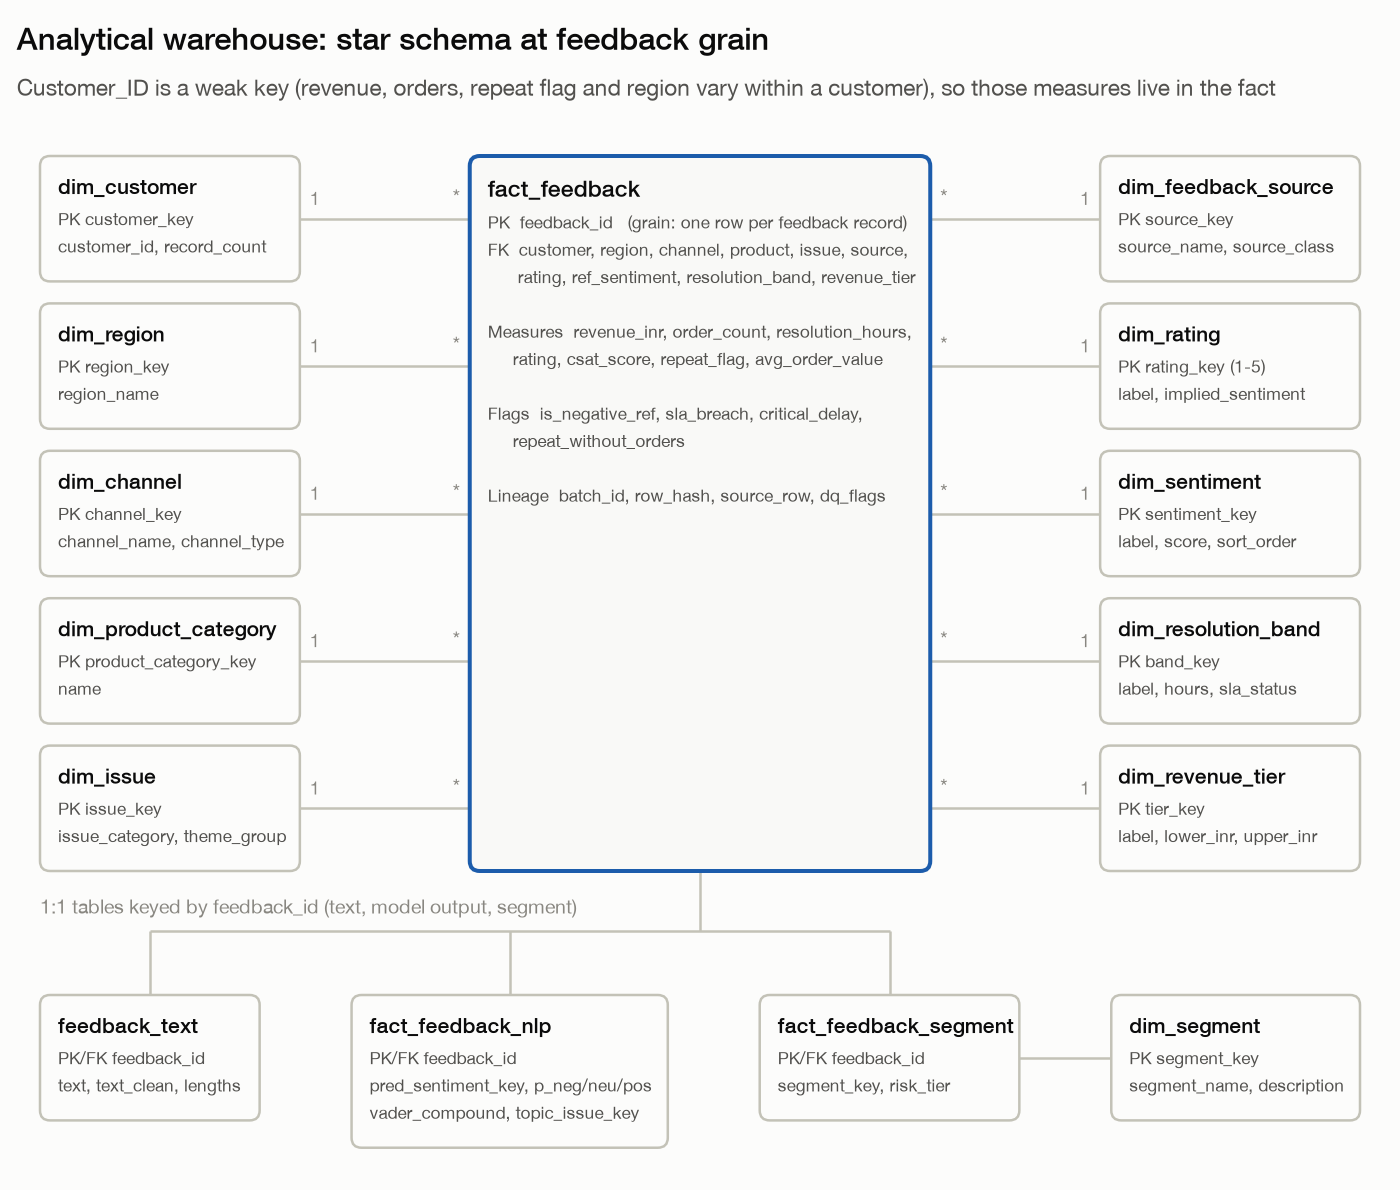

-- =============================================================================
-- CVI Analytical Warehouse  |  Project MSDS-MAJOR-CVI-001  |  Engine: SQLite 3
-- Pattern : Kimball star schema, Type-1 dimensions (no history - the source has
--           no date field), surrogate integer keys, enforced FK/CHECK constraints.
-- Grain   : fact_feedback = ONE ROW PER FEEDBACK RECORD (Feedback_ID).
-- NOTE    : Customer_ID is a weak entity key - revenue, orders, repeat flag and
--           region vary between the records of the same Customer_ID, so those
--           values live in the FACT (record level) and are never rolled up to a
--           customer attribute.
-- =============================================================================
PRAGMA foreign_keys = ON;

-- ------------------------------- DIMENSIONS ----------------------------------
CREATE TABLE dim_region (
    region_key           INTEGER PRIMARY KEY,
    region_name          TEXT    NOT NULL UNIQUE
);

CREATE TABLE d

,check_id,description,expected,actual,status
0,WH-01,fact_feedback rows == Silver rows,2400.00,2400.00,PASS
1,WH-02,feedback_text rows == Silver rows,2400.00,2400.00,PASS
2,WH-03,distinct feedback_id in fact == Silver,2400.00,2400.00,PASS
3,WH-04,"SUM(customer_revenue_inr) fact == Silver (INR, tol 0.01)",15124903.57,15124903.57,PASS
4,WH-05,dim_customer rows == distinct Customer_ID,1114.00,1114.00,PASS
5,WH-06,Foreign-key violations (PRAGMA foreign_key_check),0.00,0.00,PASS
6,WH-07,SQLite integrity_check returns 'ok',1.00,1.00,PASS
7,WH-08,Fact rows with NULL dimension keys,0.00,0.00,PASS
8,WH-09,SUM(order_count) fact == Silver,15548.00,15548.00,PASS
9,WH-10,vw_feedback_360 rows == fact rows (no join fan-out),2400.00,2400.00,PASS


,value
feedback_count,2.400000e+03
negative_sentiment_rate,2.404000e-01
positive_sentiment_rate,5.708000e-01
net_sentiment_score,3.304000e+01
repeat_purchase_rate,5.746000e-01
avg_resolution_hours,1.125600e+01
avg_csat,3.462000e+00
avg_rating,3.481000e+00
total_revenue_inr,1.512490e+07
revenue_at_risk_inr,3.703115e+06


,issue_category,feedback_count,topic_share,negative_sentiment_rate,repeat_purchase_rate,avg_resolution_hours,revenue_at_risk_inr
0,Customer Support,300,0.1250,0.2867,0.5733,11.707,552222.38
1,App Experience,298,0.1242,0.2617,0.5705,11.719,541983.06
2,Delivery Delay,296,0.1233,0.2432,0.5709,11.420,483194.97
3,Refund Delay,299,0.1246,0.2408,0.5585,11.035,425151.84
4,Packaging,271,0.1129,0.2399,0.5978,11.007,441237.23
5,Pricing,323,0.1346,0.2198,0.5789,11.196,448018.14
6,Product Quality,298,0.1242,0.2181,0.6107,11.312,408231.36
7,Product Availability,315,0.1313,0.2159,0.5397,10.668,403076.03


In [6]:
fig("fig02_star_schema_erd", 820)
print(open(C.SQL_DIR / "schema.sql").read()[:1500], "...")
display(pd.read_csv(C.VALIDATION_DIR / "warehouse_reconciliation.csv"))
display(W.query("SELECT * FROM vw_kpi_overall").T.rename(columns={0: "value"}))
display(W.query("SELECT issue_category, feedback_count, topic_share, negative_sentiment_rate, repeat_purchase_rate, avg_resolution_hours, revenue_at_risk_inr FROM vw_kpi_by_issue ORDER BY negative_sentiment_rate DESC"))

## Activity 5 - Exploratory business analytics
No pattern is reported without an effect size, an uncertainty statement and (when many cells are scanned) a multiple-testing correction.

In [7]:
df = transform.load_silver()
# Pattern 1: sentiment vs repeat purchase (chi-square + Cramer's V)
ct = pd.crosstab(df.reference_sentiment, df.repeat_purchase_flag)
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"repeat purchase by sentiment: chi2={chi2:.1f}, p={p:.1e}, Cramer's V={np.sqrt(chi2 / (ct.values.sum())):.2f}")
print((df.groupby("reference_sentiment").repeat_purchase_flag.mean() * 100).round(1).to_dict())
# Pattern 2: resolution time
neg, non = df[df.is_negative_ref == 1].resolution_time_hours, df[df.is_negative_ref == 0].resolution_time_hours
print(f"resolution: negative {neg.mean():.1f} h vs other {non.mean():.1f} h | Mann-Whitney p={stats.mannwhitneyu(neg, non).pvalue:.1e}")
# Null results: segment dimensions vs sentiment
for dim in ["issue_category", "channel", "region", "product_category", "feedback_source"]:
    c2 = pd.crosstab(df[dim], df.reference_sentiment); print(f"  {dim:18s} chi-square p = {stats.chi2_contingency(c2)[1]:.2f}")
display(pd.DataFrame(M["eda"]["material_patterns"])[["id", "type", "pattern", "evidence"]])

repeat purchase by sentiment: chi2=329.5, p=2.9e-72, Cramer's V=0.37
{'Negative': 28.2, 'Neutral': 50.6, 'Positive': 72.0}
resolution: negative 18.1 h vs other 9.1 h | Mann-Whitney p=7.7e-193
  issue_category     chi-square p = 0.33
  channel            chi-square p = 0.27
  region             chi-square p = 0.69
  product_category   chi-square p = 0.79
  feedback_source    chi-square p = 0.82


,id,type,pattern,evidence
0,P1,signal,Negative feedback is strongly tied to lower repeat purchase,"repeat rate Negative 28.2% vs Neutral 50.6% vs Positive 72.0% (chi2=329, p=2.9e-72, Cr..."
1,P2,signal,Negative cases take about twice as long to resolve,mean resolution 18.1h (negative) vs 9.1h (non-negative); Cohen's d=1.90; resolution ti...
2,P3,signal,Rating and CSAT are near-redundant measures of the same experience,"Spearman rho(rating, CSAT)=0.97; both fall with resolution time (rho=-0.46)"
3,P4,null,"No issue, channel, region, product or source is significantly worse than the rest","chi-square p-values Issue 0.33, Channel 0.27, Region 0.69, Product 0.79, Source 0.82; ..."
4,P5,null,Revenue and order count are unrelated to sentiment (negative feedback is not confined ...,"mean revenue Negative INR 6,418 vs Positive INR 6,233 (Kruskal p=0.46); revenue is sta..."


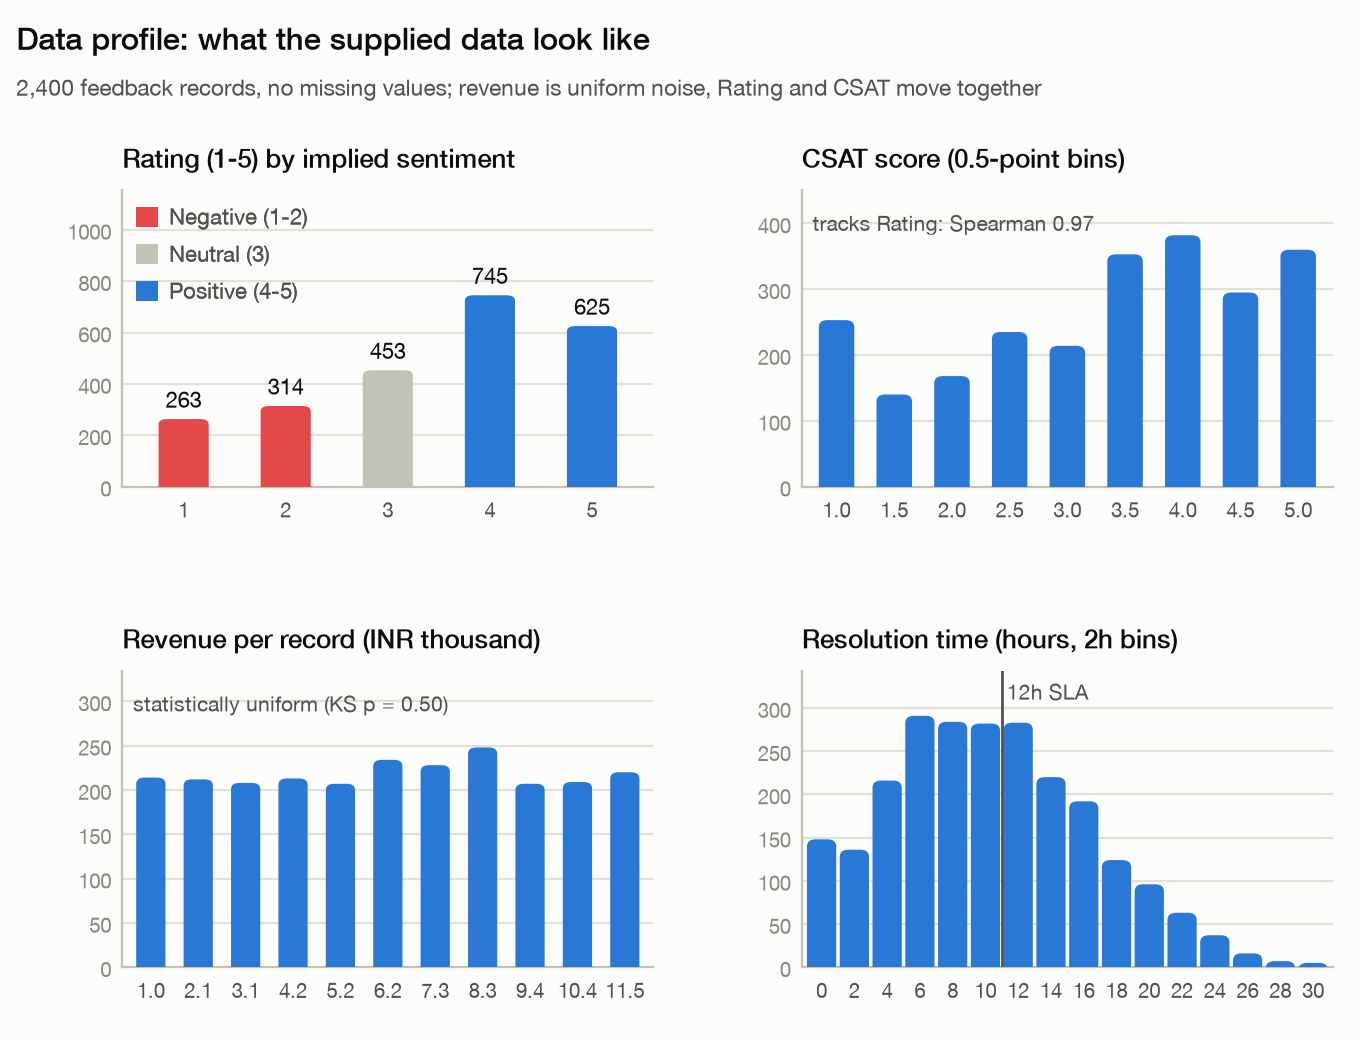

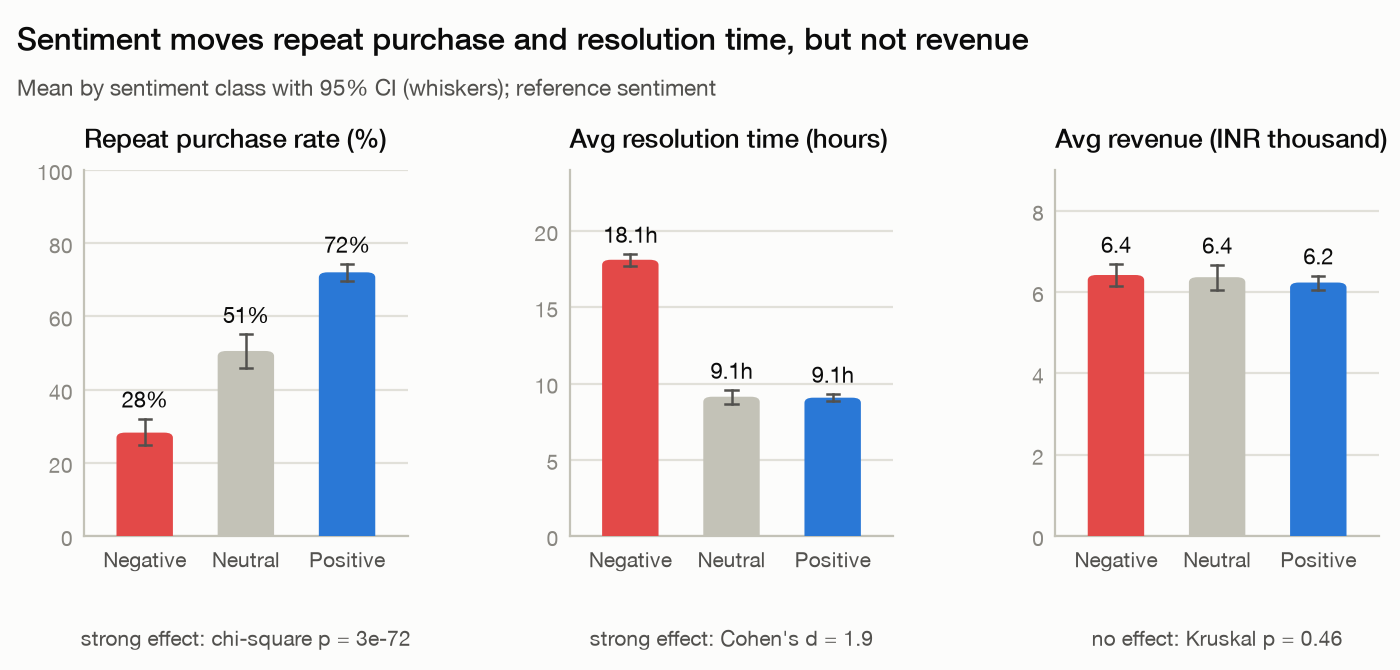

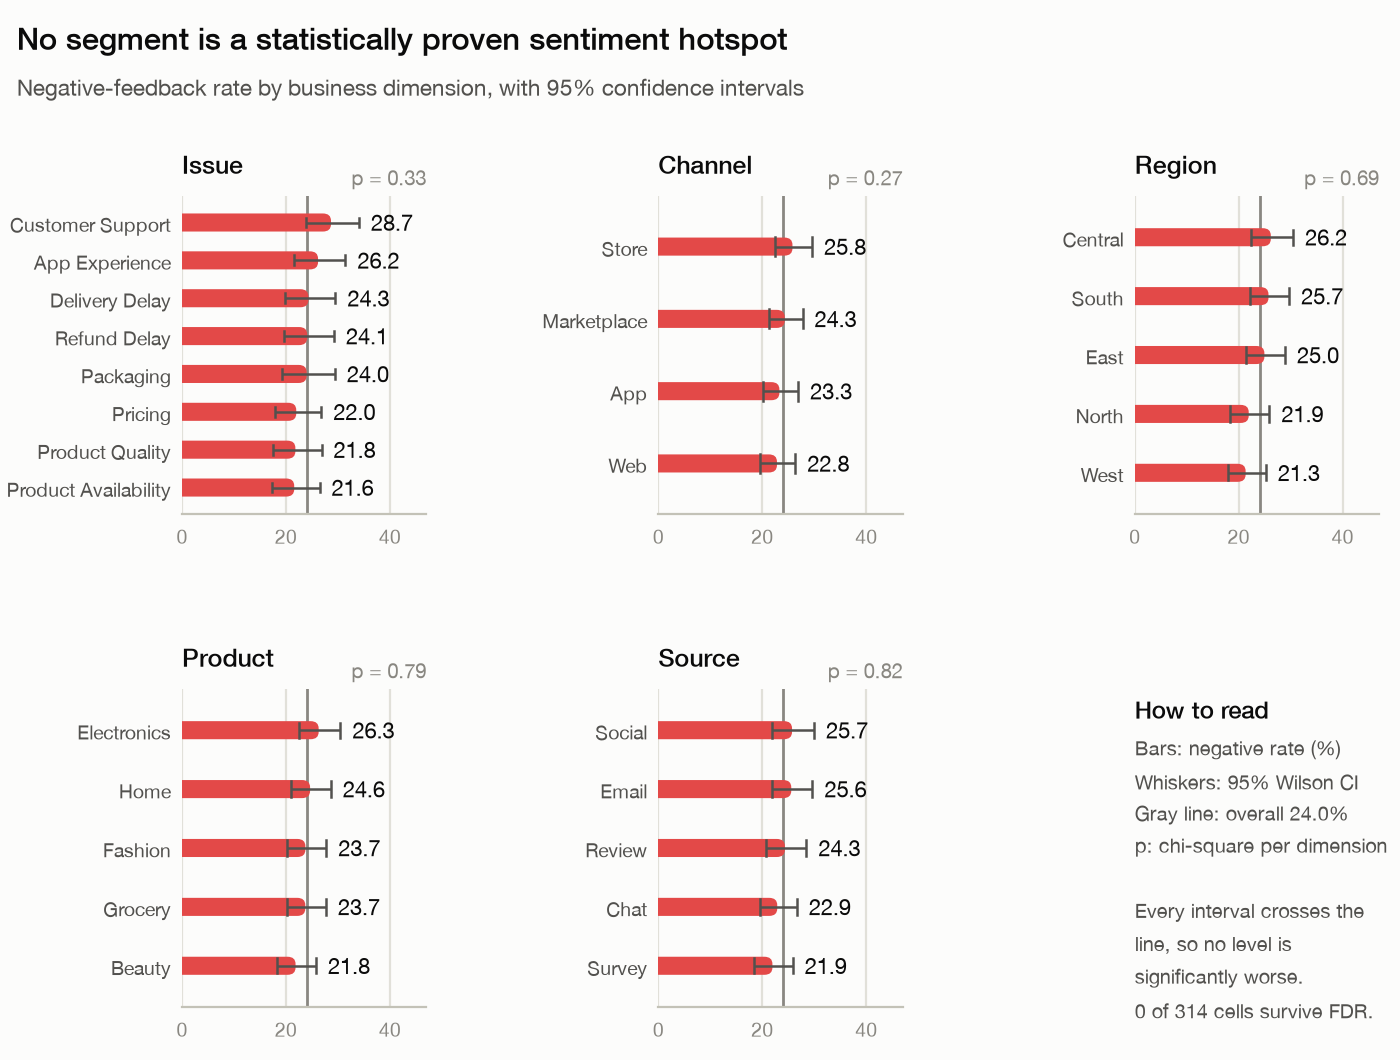

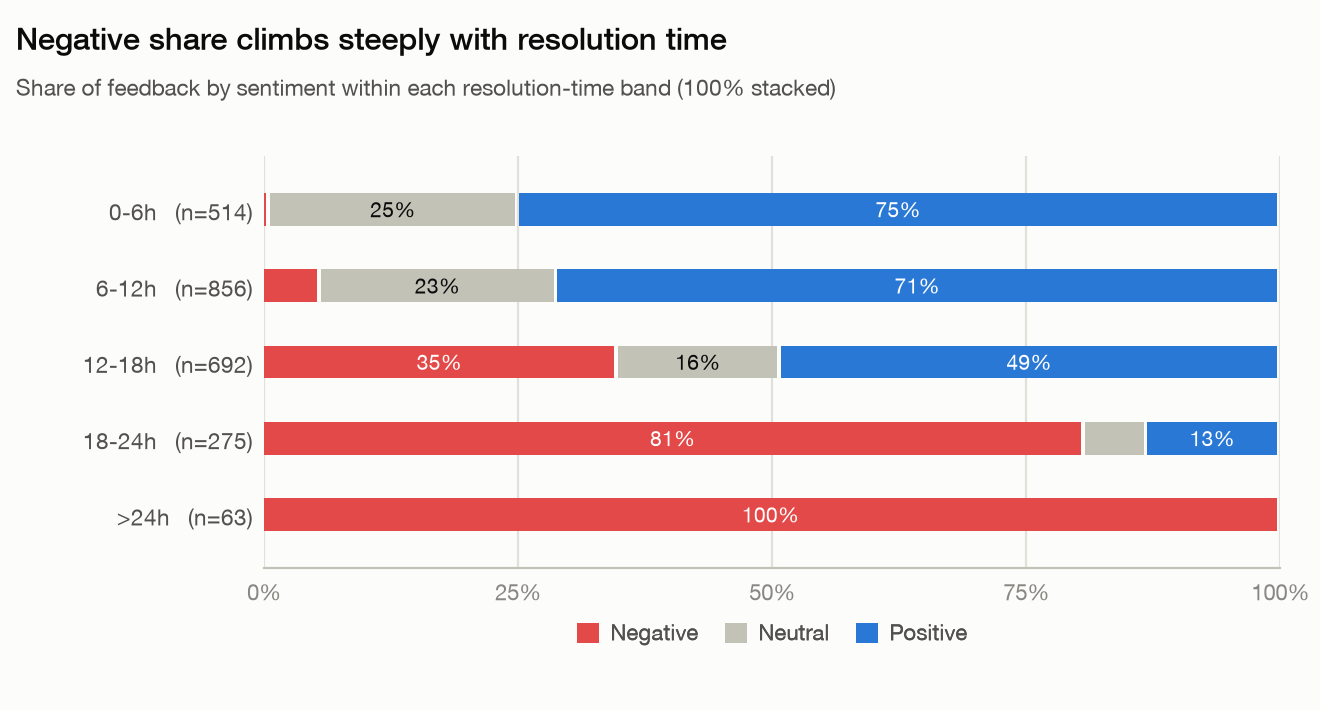

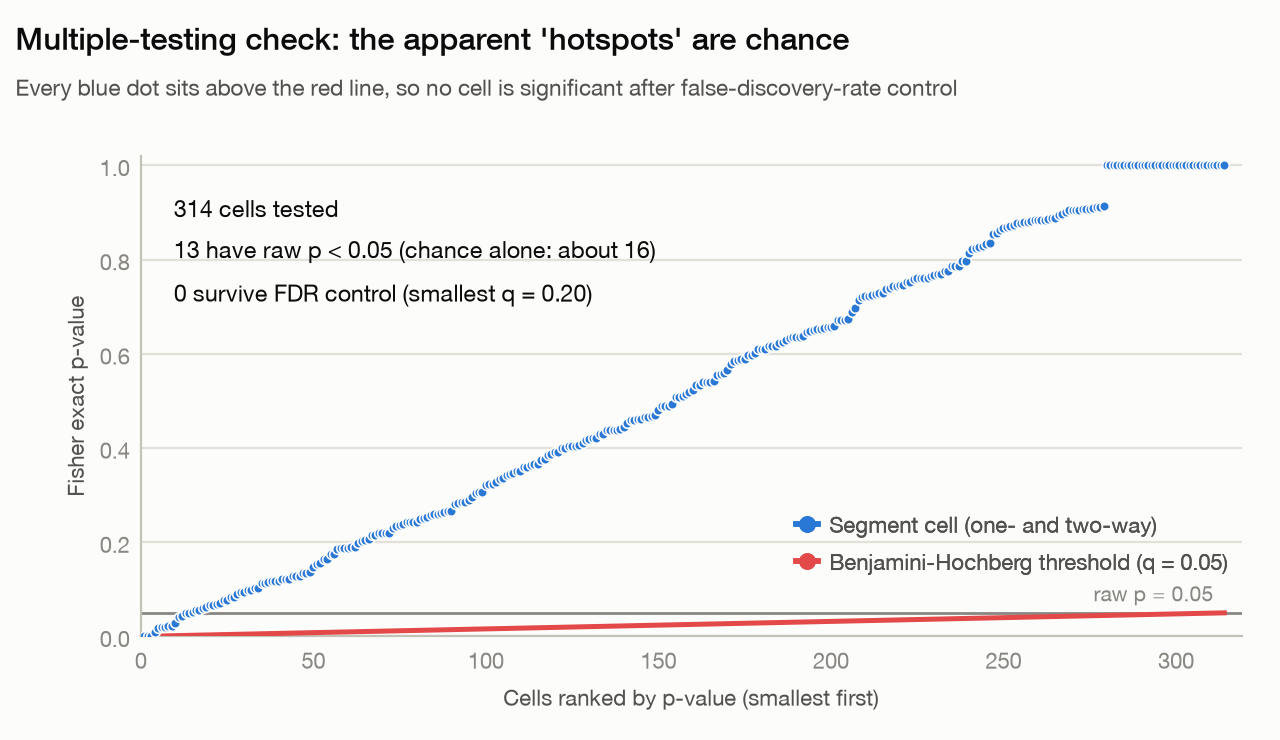

In [8]:
for f in ["fig03_data_profile", "fig07_sentiment_vs_outcomes", "fig06_negative_rate_by_dimension", "fig09_sentiment_by_resolution_band", "fig11_fdr_hotspot_scan"]:
    fig(f)

## Activity 6 - Data mining
K-means is compared with a **column-permutation null** (a good-looking silhouette is not evidence of clusters); association rules go through a Fisher + FDR + productivity funnel.

,k,inertia,silhouette,calinski_harabasz,davies_bouldin,null_silhouette_mean,null_silhouette_p95,beats_null,silhouette_lift_over_null,smallest_cluster_share
0,2,4126.339,0.413,1786.265,1.004,0.365,0.366,True,0.047,0.305
1,3,2593.859,0.459,2128.281,0.863,0.353,0.357,True,0.105,0.244
2,4,2040.699,0.453,2019.208,0.860,0.347,0.365,True,0.106,0.131
3,5,1612.347,0.415,2074.993,0.866,0.372,0.379,True,0.043,0.090
4,6,1387.041,0.397,2006.606,0.955,0.383,0.390,True,0.014,0.090
5,7,1194.650,0.397,2004.883,0.919,0.382,0.388,True,0.015,0.075
6,8,1035.849,0.378,2033.490,0.918,0.377,0.380,False,0.000,0.075


,segment_name,feedback_count,negative_rate,avg_csat,avg_resolution_hours,repeat_rate,revenue_at_risk_inr,rar_share_of_total
0,At-Risk,586,0.937,1.671,18.493,0.258,3547183.78,0.958
1,Loyal Repeaters,1228,0.015,4.123,8.972,1.000,83195.08,0.022
2,Satisfied Non-Repeaters,586,0.017,3.866,8.805,0.000,72736.15,0.020


rule funnel: {'frequent_itemsets': 2469, 'rules_all_lift_ge_1': 6827, 'rules_with_target_consequent': 339, 'rules_lift_ge_1.2': 158, 'rules_significant_fdr_assoc': 157, 'rules_robust_after_productivity': 7, 'robust_rules_using_only_context_dimensions': 0, 'robust_rules_containing_any_context_item': 0}


,antecedent,consequent,antecedent_size,support,confidence,lift,leverage,conviction,best_parent_confidence,p_assoc,p_productive,q_final_bh
0,Repeat=No & Resolution=>18h,Sentiment=Negative,2,0.087,0.905,3.763,0.064,7.976,0.843,0.0,0.0,0.0
1,Resolution=>18h,Sentiment=Negative,1,0.119,0.843,3.507,0.085,4.844,NaN,0.0,0.0,0.0
2,Repeat=No & Resolution=12-18h,Sentiment=Negative,2,0.072,0.521,2.167,0.039,1.586,0.405,0.0,0.0,0.0
3,Repeat=No,Sentiment=Negative,1,0.172,0.405,1.687,0.070,1.278,NaN,0.0,0.0,0.0
4,Sentiment=Negative,Repeat=No,1,0.172,0.718,1.687,0.070,2.034,NaN,0.0,0.0,0.0
5,Resolution=>18h,Repeat=No,1,0.096,0.683,1.607,0.036,1.815,NaN,0.0,0.0,0.0
6,Resolution=12-18h,Sentiment=Negative,1,0.100,0.348,1.449,0.031,1.165,NaN,0.0,0.0,0.0


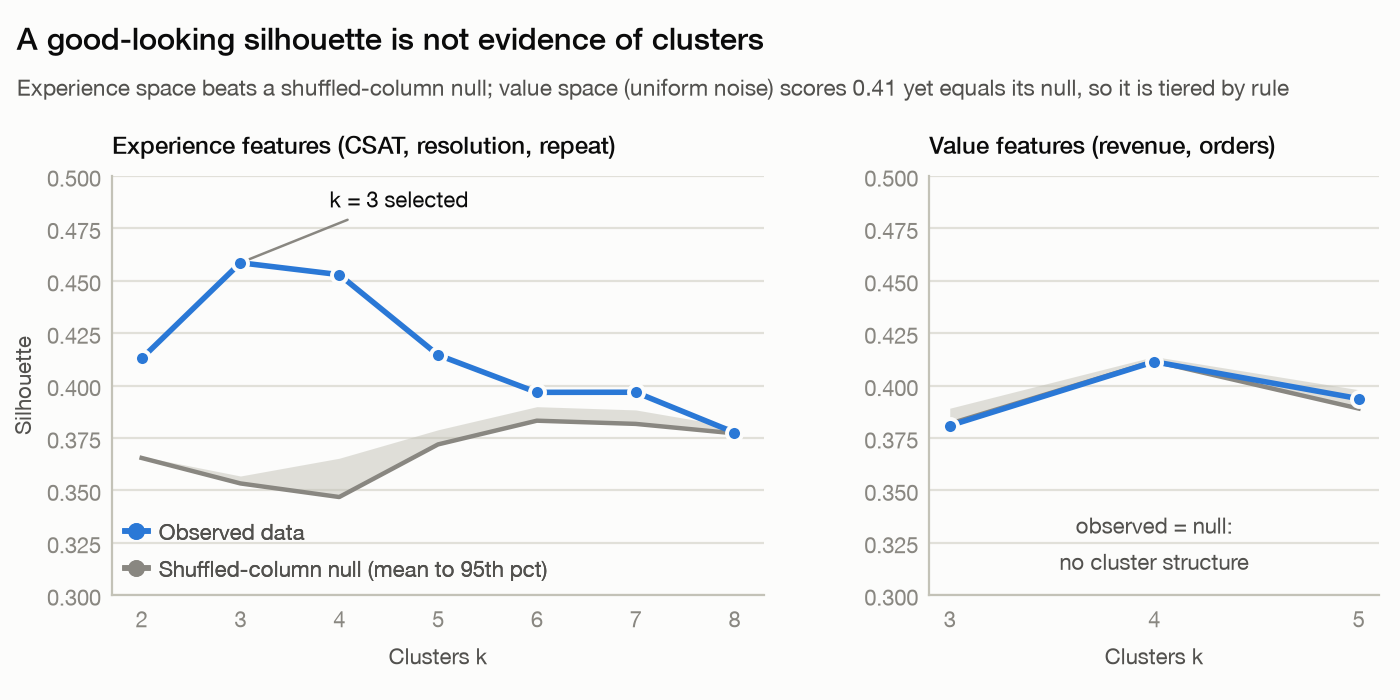

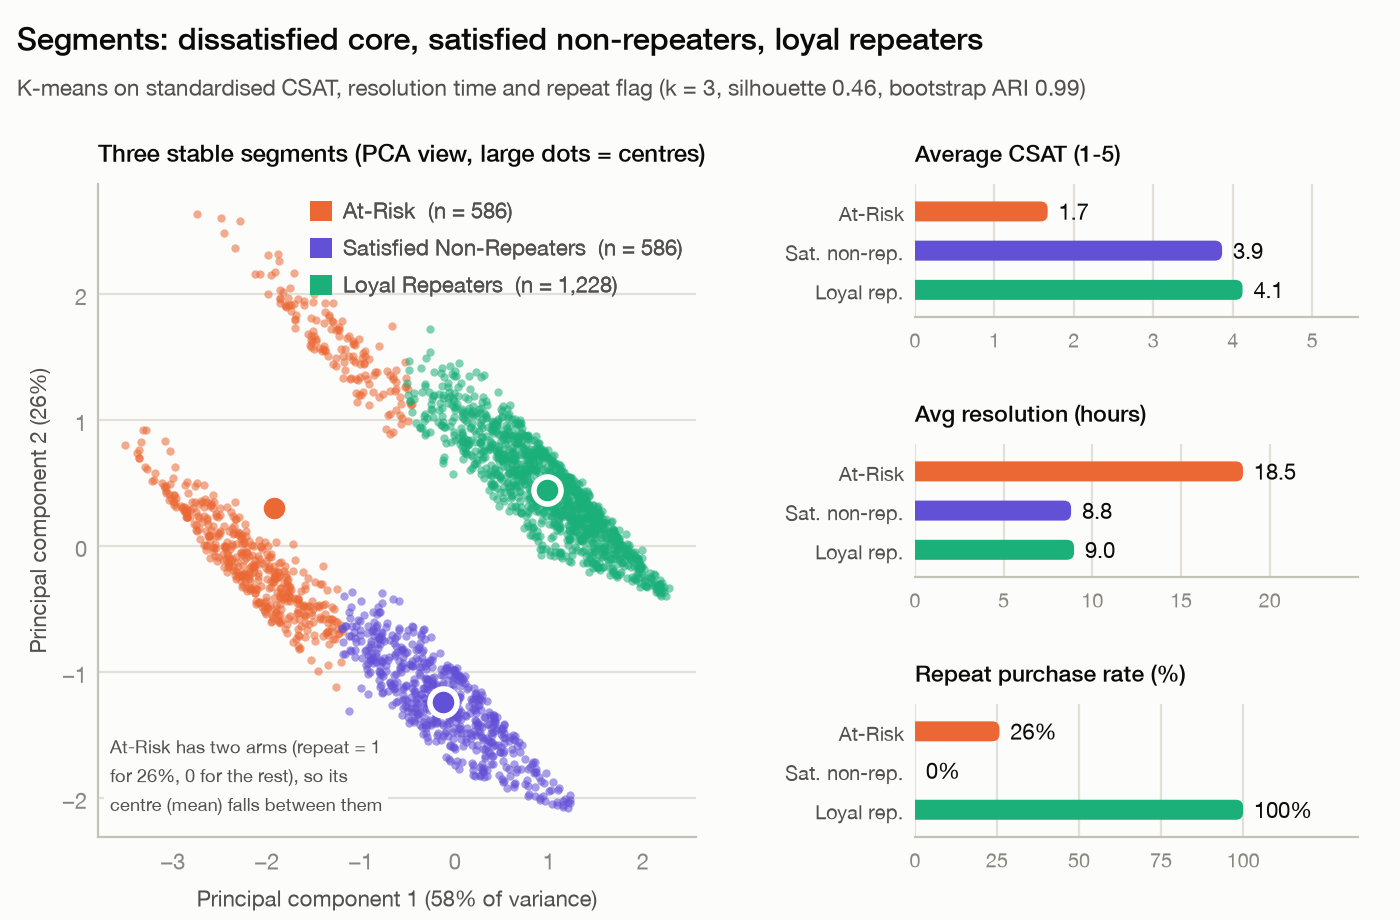

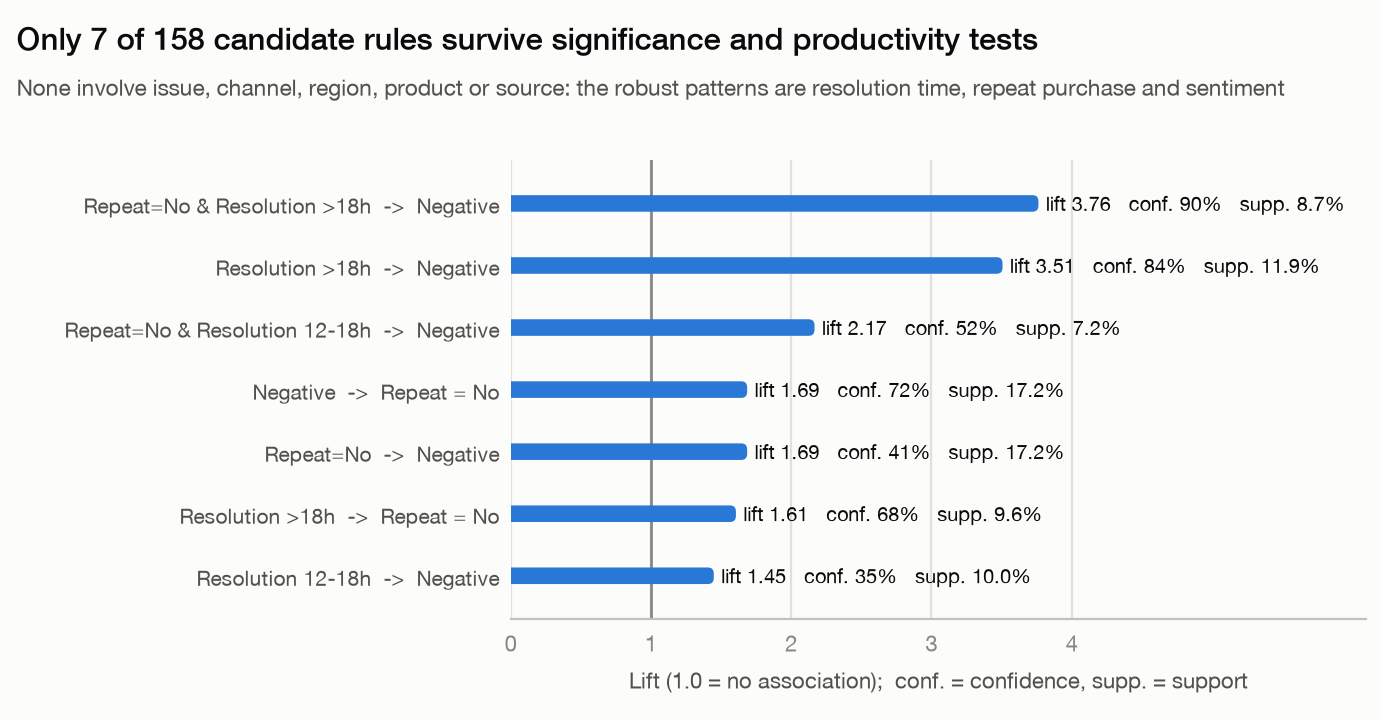

In [9]:
sel = table("mining_cluster_selection"); display(sel.round(3))
display(table("mining_segment_profile")[["segment_name", "feedback_count", "negative_rate", "avg_csat", "avg_resolution_hours", "repeat_rate", "revenue_at_risk_inr", "rar_share_of_total"]].round(3))
print("rule funnel:", M["mining"]["association_rules"]["funnel"])
display(table("mining_association_rules_robust").round(3))
for f in ["fig19_cluster_selection", "fig20_segments", "fig21_association_rules"]:
    fig(f)

## Activity 7 - NLP pre-processing
A 10-step workflow (negation marking, lemmatisation, data-driven boilerplate removal), one object used in training, scoring and the dashboard.

In [10]:
display(nlp_prep.describe_steps())
pre = nlp_prep.TextPreprocessor()
samples = ["The app experience experience was helpful. I used the web channel for my fashion order and this affected my overall experience.",
           "The delivery wasn't good, and the courier didn't call! Visit https://x.co or mail a@b.com <b>NOW</b> @brand #fail",
           "Not happy. Never again; refund delayed by 12 days -- very very disappointed"]
display(nlp_prep.before_after_examples(samples, pre))
st = nlp_prep.corpus_stats(nlp_prep.TextPreprocessor(return_tokens=True).transform(df.text_clean))
print({k: v for k, v in st.items() if k != "top_terms"})

,step,operation,why_it_is_required
0,1,Unicode NFKC + whitespace collapse,Canonical character representation
1,2,"Strip HTML, URLs, e-mails, @mentions/#hashtags","Channel noise (reviews, social) carries no sentiment"
2,3,Lowercase,Merge case variants; reduce sparsity
3,4,Expand contractions (n't -> not),Make negation explicit for step 7
4,5,Collapse repeated adjacent words (intensifiers/negators excepted),Repair template glitch 'experience experience'
5,6,Clause split + regex tokenisation (letters/apostrophes only),Negation scope bounded by punctuation; drop digits/punctuation
6,7,Negation marking: NOT_ prefix on next 3 tokens in the clause,'not good' must not be confused with 'good'
7,8,Stop-word removal (NLTK English; negators/intensifiers kept),"Remove function words, keep polarity cues"
8,9,"WordNet lemmatisation (noun, then verb)",Consolidate inflections (delays/delayed -> delay)
9,10,"Boilerplate removal by document frequency (BoilerplateFilter, max_df=0.90, before n-gr...",Terms present in >=90% of texts have no discriminative value; learned on training data...


,raw_text,processed_tokens
0,The app experience experience was helpful. I used the web channel for my fashion order...,app experience helpful use web channel fashion order affect overall experience
1,"The delivery wasn't good, and the courier didn't call! Visit https://x.co or mail a@b....",delivery not NOT_good courier not NOT_call visit mail
2,Not happy. Never again; refund delayed by 12 days -- very very disappointed,not NOT_happy never refund delay day very very disappoint


{'documents': 2400, 'tokens_total': 27908, 'vocabulary_size': 44, 'avg_tokens_per_doc': 11.63, 'hapax_terms': 0, 'boilerplate_terms_df_ge_90pct': ['affect', 'channel', 'experience', 'order', 'overall', 'use']}


## Activity 8 - Sentiment analysis
Six approaches, three evaluation regimes. **Read the numbers carefully:** the 100% scores are a ceiling effect of templated text; leave-one-opinion-word-out shows what happens on unseen vocabulary.

accuracy                macro_f1               
regime                                    cv5 holdout   lodo      cv5 holdout   lodo
model                                                                               
Baseline: majority class                0.571   0.571  0.571    0.242   0.242  0.242
Hybrid: TF-IDF + VADER features (LR)    1.000   1.000  0.579    1.000   1.000  0.400
TF-IDF + Linear SVM                     1.000   1.000  0.571    1.000   1.000  0.242
TF-IDF + Logistic Regression            1.000   1.000  0.571    1.000   1.000  0.242
TF-IDF + Multinomial NB                 1.000   1.000  0.571    1.000   1.000  0.242
VADER lexicon (+/-0.05)                 0.606   0.604  0.606    0.478   0.470  0.478

ablation (accuracy): {'Full text': 1.0, 'Descriptor word MASKED (topic / channel / produc': 0.342, 'Descriptor word ONLY': 1.0, 'Majority-class baseline': 0.571}
30-sentence natural-language probe: {'TF-IDF+LR (trained on supplied data)': 0.7, 'Hybrid TF-IDF+VADER': 0.87, 'VADER lexicon': 0.8} (qualitative, n=30)


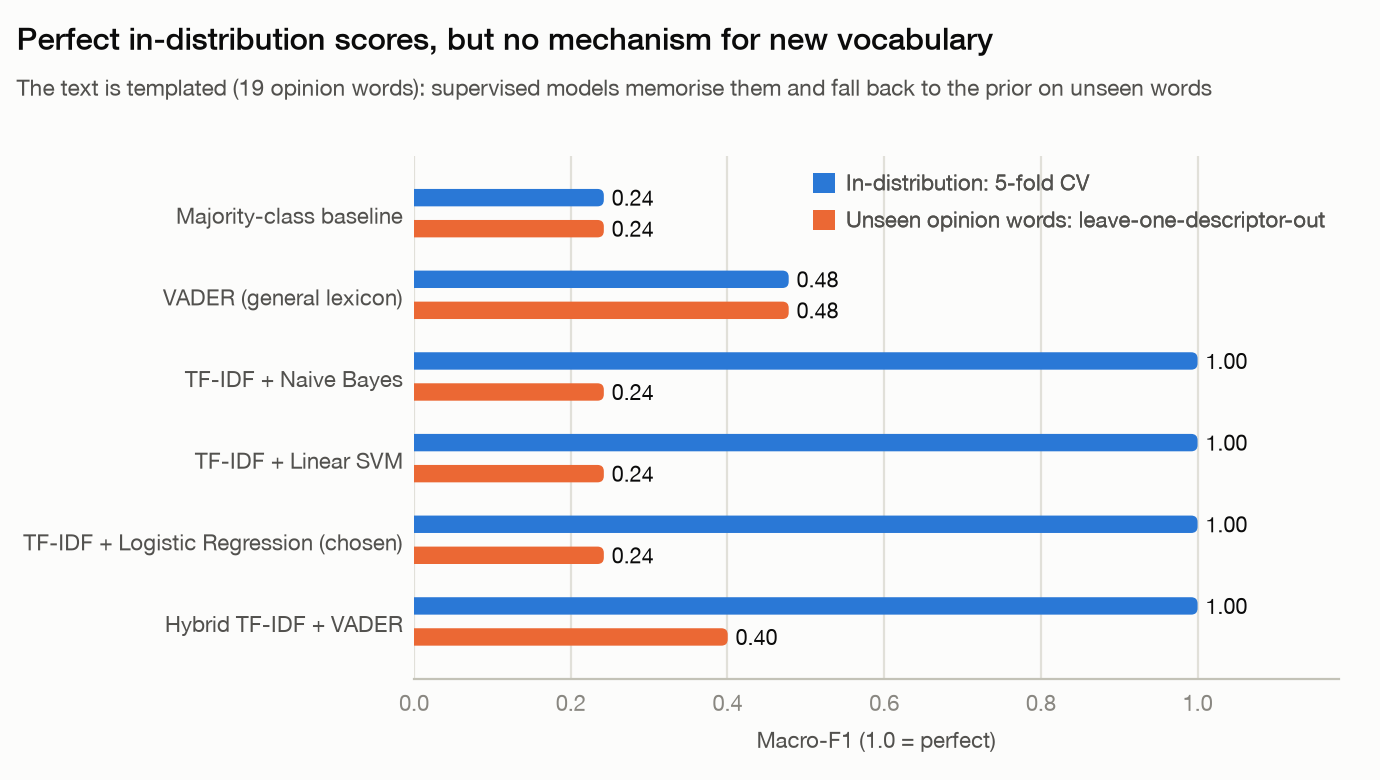

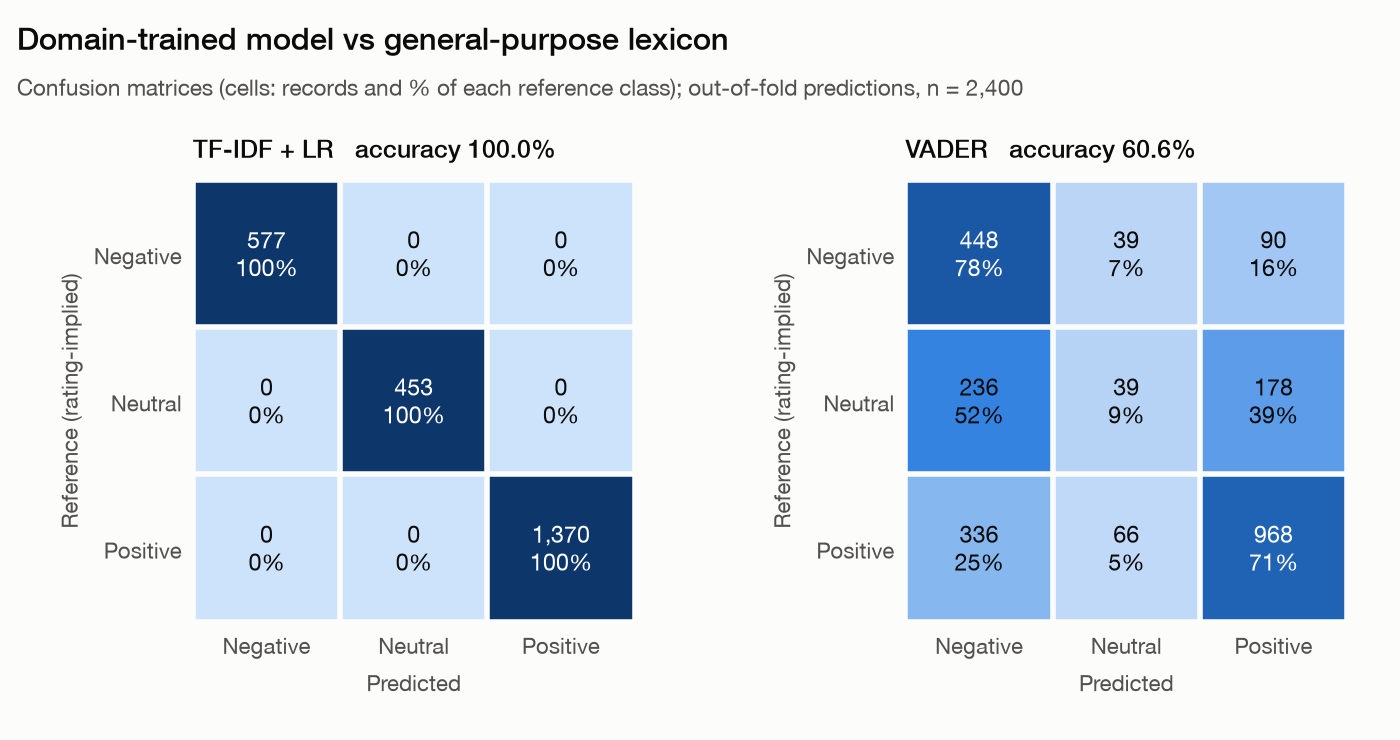

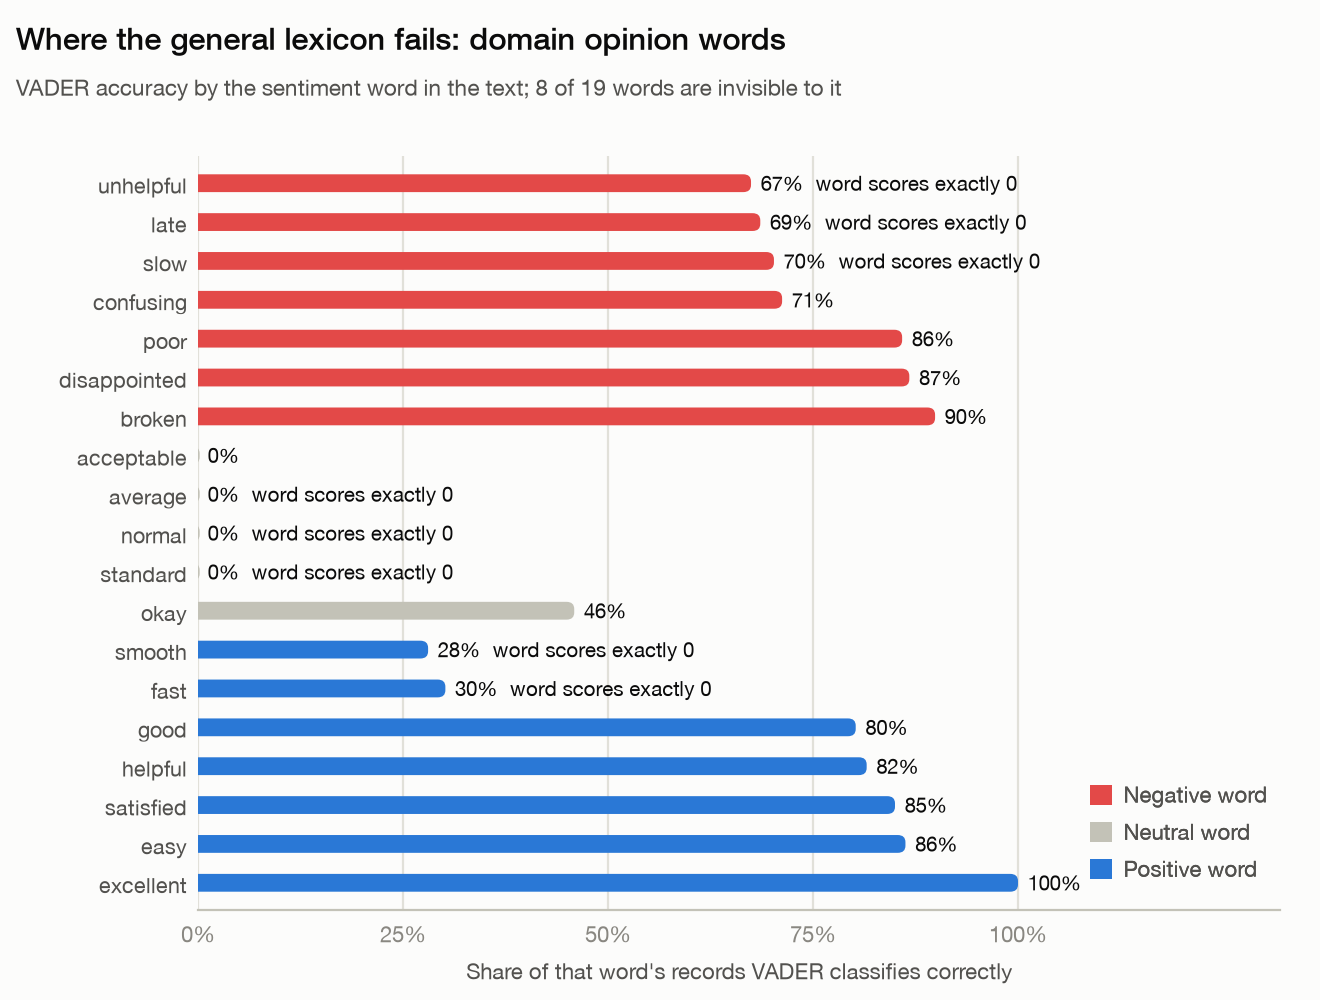

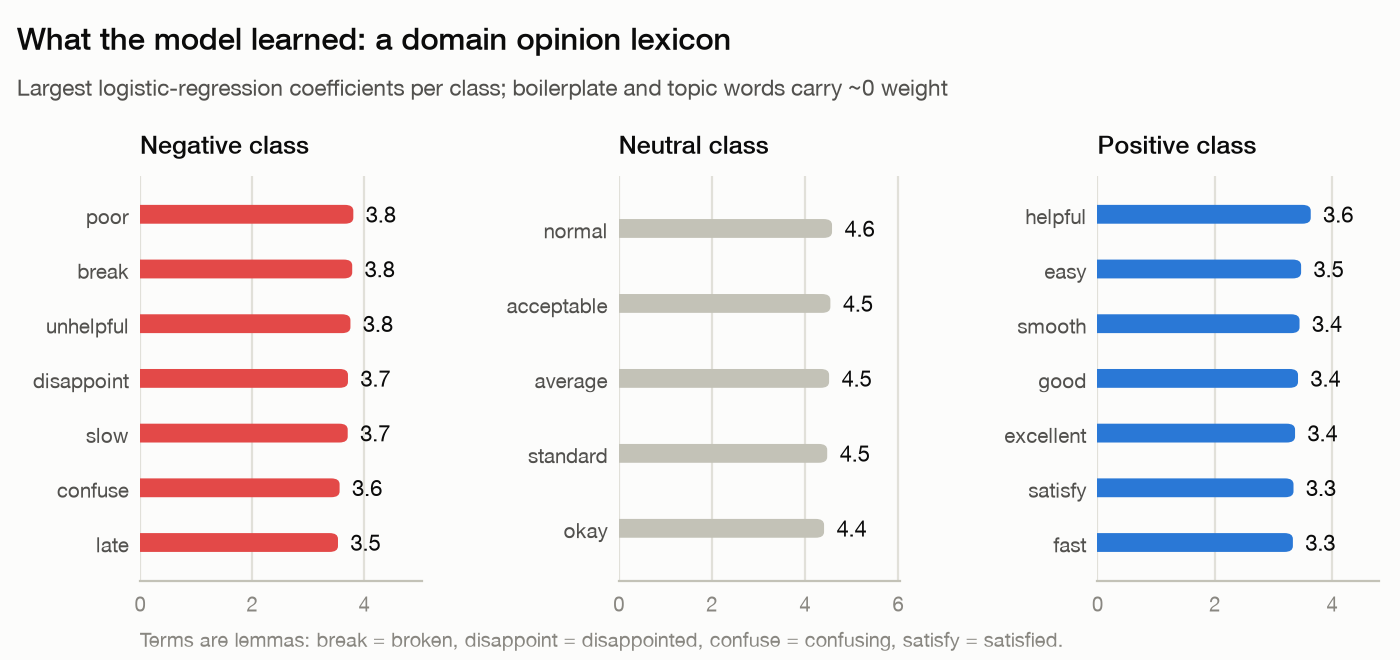

In [11]:
comp = table("sentiment_model_comparison")
display(comp.pivot_table(index="model", columns="regime", values=["accuracy", "macro_f1"]).round(3))
s = M["sentiment"]
print("ablation (accuracy):", {k[:48]: round(v, 3) for k, v in s["ablation"].items()})
print("30-sentence natural-language probe:", {k: round(v, 2) for k, v in s["ood_probe_accuracy"].items()}, "(qualitative, n=30)")
for f in ["fig12_nlp_model_comparison", "fig13_confusion_matrices", "fig14_vader_by_descriptor", "fig15_learned_lexicon"]:
    fig(f)

In [12]:
# Score new text with the saved production model, next to the general-purpose lexicon
new = ["The delivery delay experience was slow. I used the app channel for my home order and this affected my overall experience.",
       "Love the new app, checkout is easy and fast.",
       "Worst service ever, never ordering again.",
       "The order arrived on the expected date."]
out = sentiment.predict_sentiment(new)
out["vader"] = sentiment.vader_label(sentiment.vader_scores(new).vader_compound)
display(out.round(2))

,text,sentiment,p_negative,p_neutral,p_positive,vader
0,The delivery delay experience was slow. I used the app channel for my home order and t...,Negative,0.95,0.02,0.03,Negative
1,"Love the new app, checkout is easy and fast.",Positive,0.00,0.00,1.00,Positive
2,"Worst service ever, never ordering again.",Negative,0.42,0.25,0.33,Negative
3,The order arrived on the expected date.,Negative,0.42,0.25,0.33,Neutral


## Activity 9 - Topic / theme intelligence
Keyword taxonomy (classify) + NMF on aspect words (discover). Topics describe what customers talk about, so the 19 opinion words are learned from sentiment association and removed first.

taxonomy accuracy vs Issue_Category: 1.0 | opinion words removed: 19
NMF: {'k': 8, 'nmi_vs_issue': 1.0, 'ari_vs_issue': 1.0, 'purity_vs_issue': 1.0, 'coherence_npmi': 0.732} | LDA: {'k': 8, 'nmi_vs_issue': 0.908, 'ari_vs_issue': 0.759, 'purity_vs_issue': 0.752, 'perplexity': 10.515, 'coherence_npmi': -0.08}


,nmf_topic_id,top_words,documents,share,majority_issue_category,purity
0,0,"availability, product",315,0.131250,Product Availability,1.0
1,1,"refund, delay",299,0.124583,Refund Delay,1.0
2,2,price,323,0.134583,Pricing,1.0
3,3,"support, customer",300,0.125000,Customer Support,1.0
4,4,app,298,0.124167,App Experience,1.0
5,5,package,271,0.112917,Packaging,1.0
6,6,"quality, product",298,0.124167,Product Quality,1.0
7,7,"delivery, delay",296,0.123333,Delivery Delay,1.0


,topic_issue,feedback_count,topic_share,negative_rate,repeat_rate,revenue_at_risk_inr,rar_share_of_total
0,Pricing,323,0.135,0.220,0.579,448018.14,0.121
1,Product Availability,315,0.131,0.216,0.540,403076.03,0.109
2,Customer Support,300,0.125,0.287,0.573,552222.38,0.149
3,Refund Delay,299,0.125,0.241,0.559,425151.84,0.115
4,App Experience,298,0.124,0.262,0.570,541983.06,0.146
5,Product Quality,298,0.124,0.218,0.611,408231.36,0.110
6,Delivery Delay,296,0.123,0.243,0.571,483194.97,0.130
7,Packaging,271,0.113,0.240,0.598,441237.23,0.119


taxonomy on free text: ['Refund Delay', 'Delivery Delay', 'App Experience']


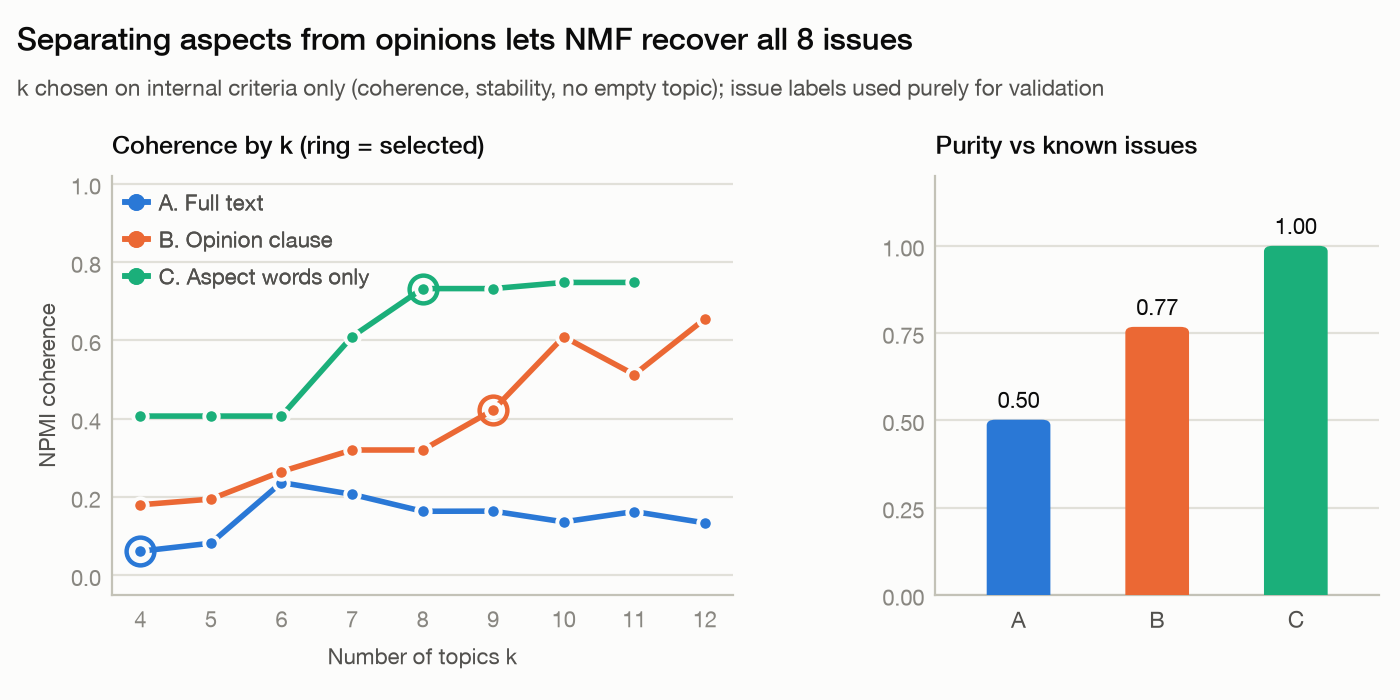

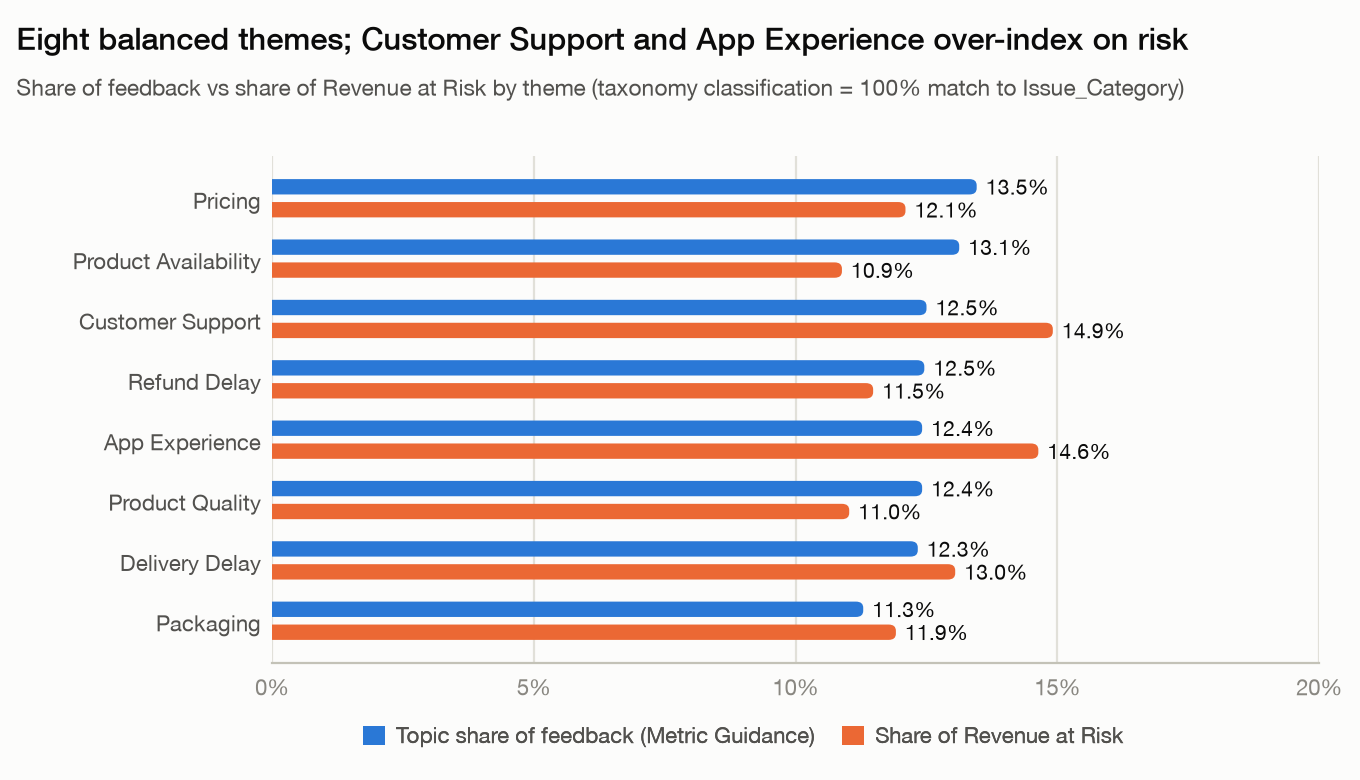

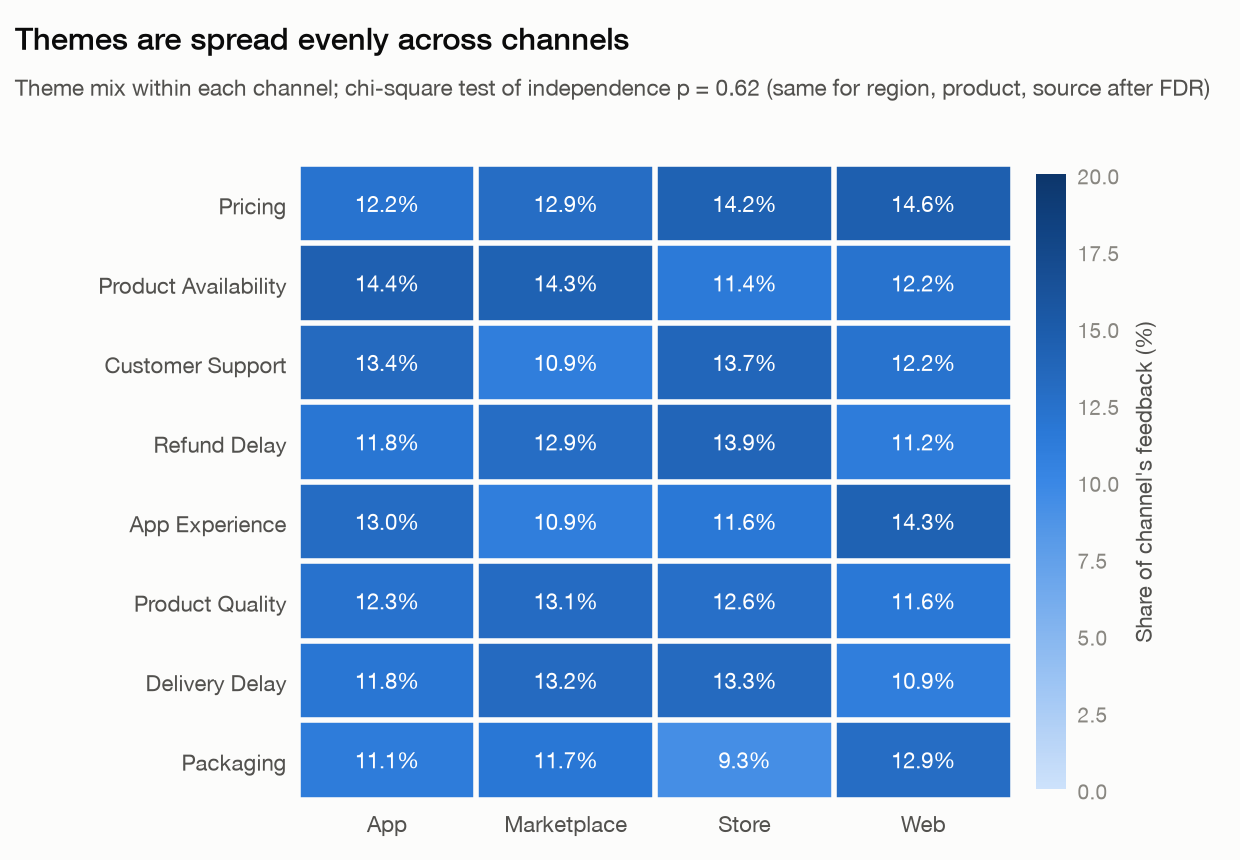

In [13]:
t = M["topics"]
print("taxonomy accuracy vs Issue_Category:", t["taxonomy_accuracy_vs_issue"], "| opinion words removed:", t["n_opinion_words"])
print("NMF:", {k: round(v, 3) if isinstance(v, float) else v for k, v in t["nmf"].items()}, "| LDA:", {k: round(v, 3) for k, v in t["lda"].items()})
display(table("topics_nmf_topics"))
display(table("topics_prevalence_relevance")[["topic_issue", "feedback_count", "topic_share", "negative_rate", "repeat_rate", "revenue_at_risk_inr", "rar_share_of_total"]].round(3))
print("taxonomy on free text:", [topics.classify_theme(x, clause_only=False) for x in ["The refund is still pending", "The courier delivered it very late", "Checkout keeps crashing in the app"]])
for f in ["fig16_topic_selection", "fig17_theme_overview", "fig18_theme_by_channel"]:
    fig(f)

## Activity 10 - Integrated customer intelligence
Text intelligence (predicted sentiment, theme) joined to revenue, repeat purchase, CSAT and resolution time in the warehouse view `vw_feedback_360`.

,sent_pred,feedback_count,repeat_rate,avg_resolution_hours,avg_csat,avg_revenue_inr
0,Negative,577,0.282,18.114,1.612,6417.877
1,Neutral,453,0.506,9.132,2.978,6364.138
2,Positive,1370,0.720,9.070,4.401,6232.725


,term,odds_ratio,ci_lo,ci_hi,p_value,label
0,res_z (alone),0.6160,0.5652,0.6714,0.0000,"Resolution time alone (per +1 SD, unadjusted)"
1,sent[T.Neutral],0.3943,0.3163,0.4916,0.0000,Neutral vs Positive sentiment
2,sent[T.Negative],0.1709,0.1302,0.2243,0.0000,Negative vs Positive sentiment
3,res_z,0.9232,0.8246,1.0336,0.1656,Resolution time (per +1 SD)
4,rev_k,0.9983,0.9721,1.0252,0.8981,"Revenue (per +INR 1,000)"
5,order_count,1.0095,0.9843,1.0352,0.4635,Order count (per +1)


Revenue at Risk INR 3,703,115 (24.5% of revenue), bootstrap 95% CI 3,428,879 - 4,013,989


,scenario,share_of_gap_recovered,recoverable_revenue_inr,ci_lo,ci_hi,pct_of_total_revenue
0,conservative,0.0,162175.0,142052.0,183065.0,0.0
1,base,0.0,405438.0,355129.0,457662.0,0.0
2,optimistic,0.0,810875.0,710258.0,915324.0,0.0


,component,records,revenue_inr,share_of_total_revenue
0,Not at risk (positive / neutral),1823,11421788.56,0.755
1,"Negative, still repeat-purchasing ('active but unhappy')",163,1053721.80,0.070
2,"Negative, no repeat purchase ('lapsed unhappy')",414,2649393.21,0.175


critical tier: {'records': 306, 'revenue_inr': 2821660.52, 'revenue_at_risk_inr': 2648895.0, 'share_of_total_rar': 0.715315347443, 'avg_resolution_hours': 18.4078431373, 'repeat_rate': 0.287581699346}
rank stability (top issue): {'level': 'Customer Support', 'p_rank1': 0.4335, 'p_top3': 0.858, 'uniform_chance': 0.125}


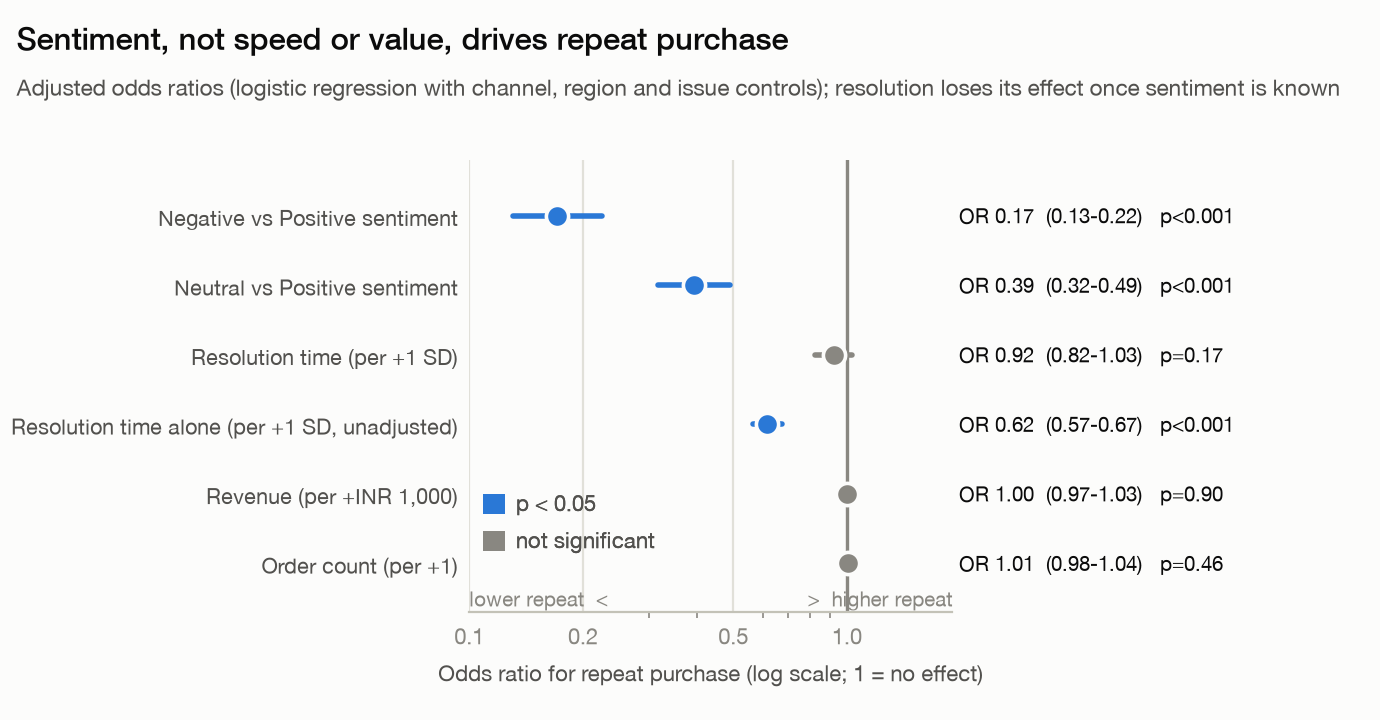

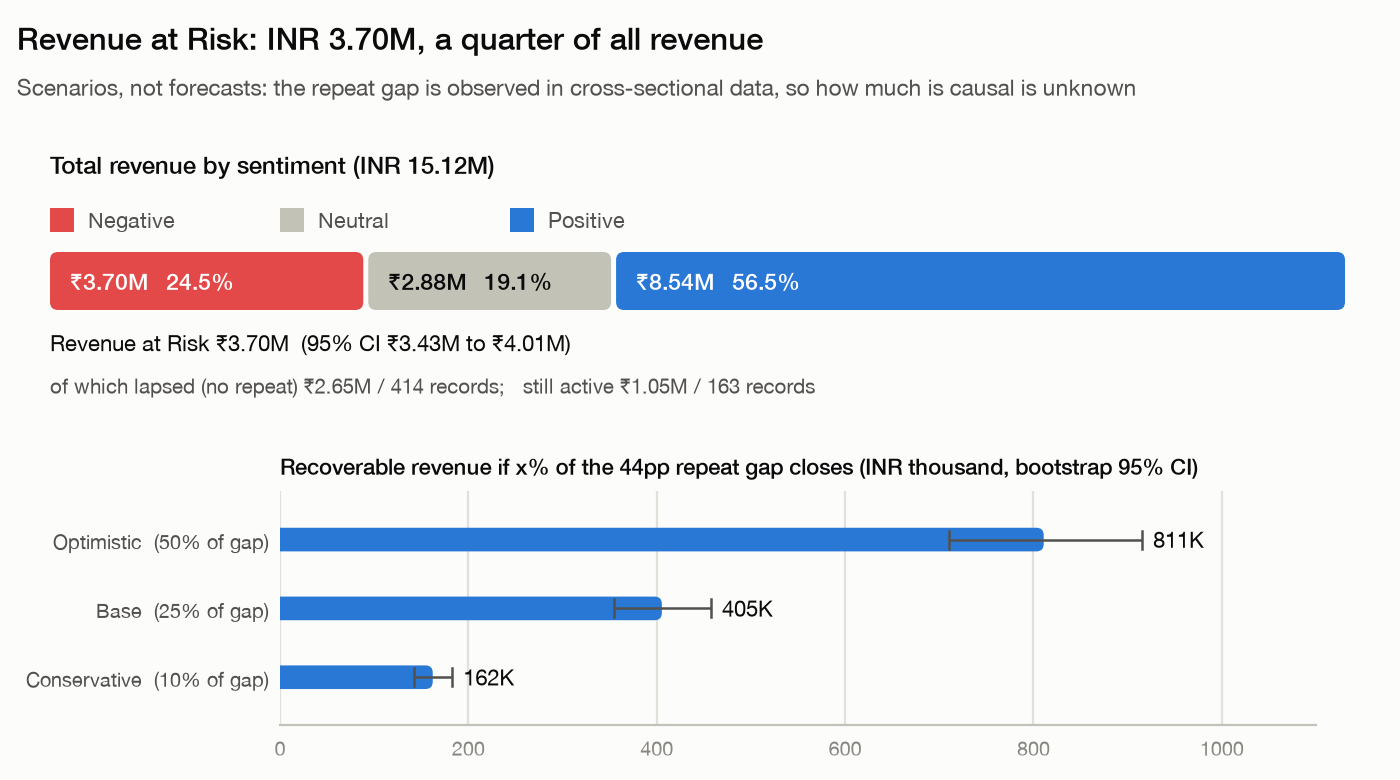

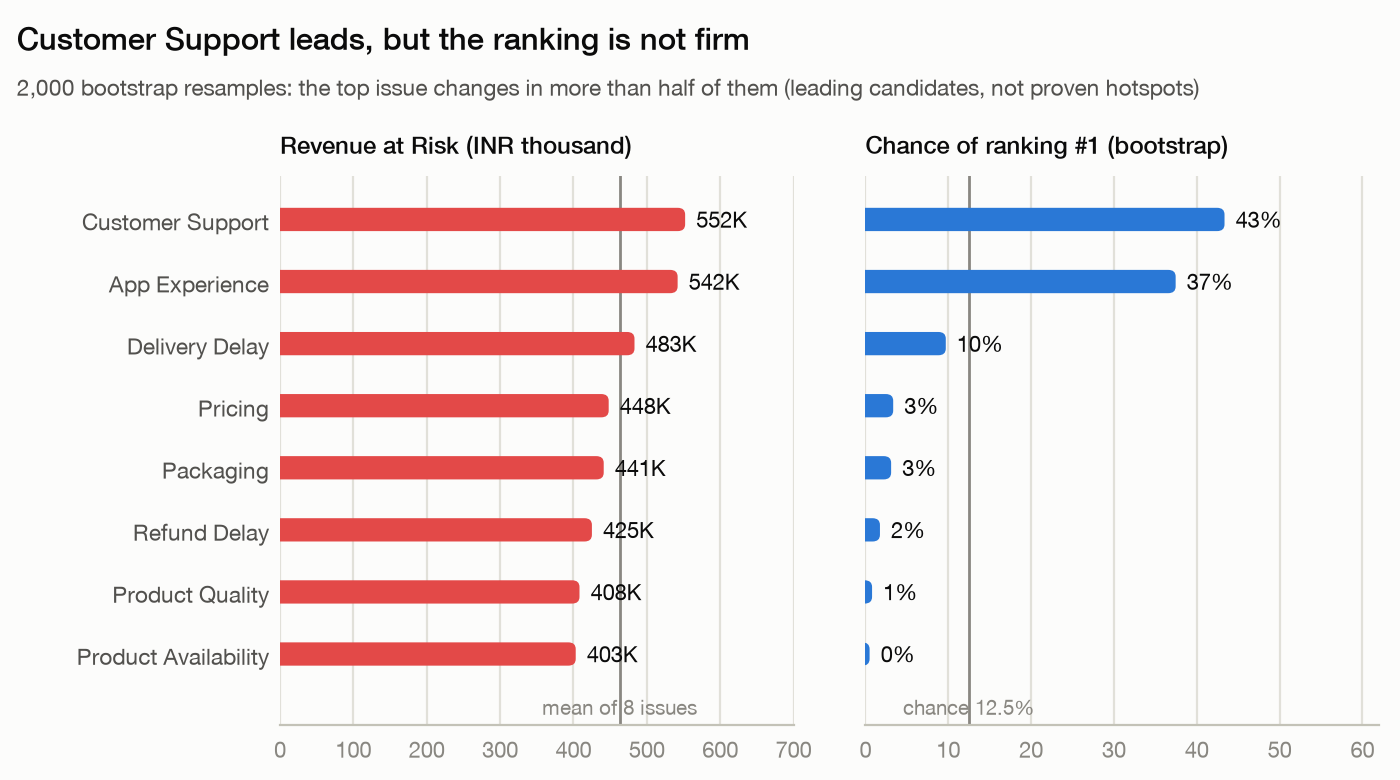

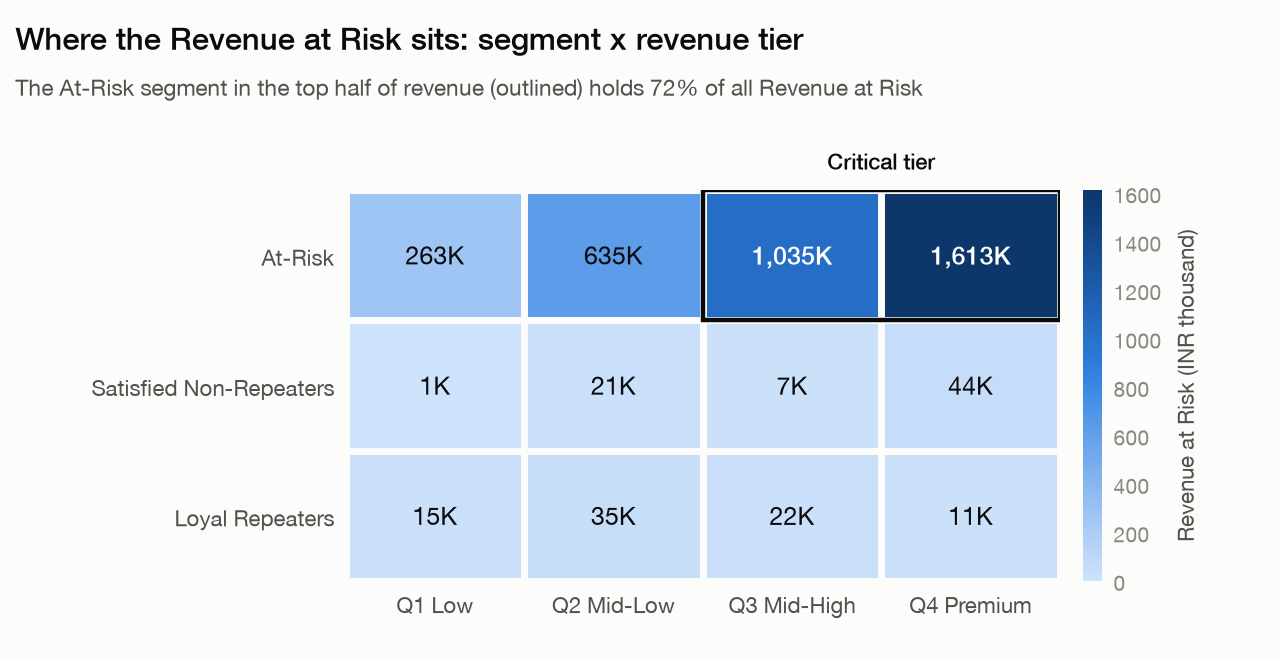

In [14]:
display(table("integrated_kpis_by_sentiment")[["sent_pred", "feedback_count", "repeat_rate", "avg_resolution_hours", "avg_csat", "avg_revenue_inr"]].round(3))
display(table("integrated_repeat_driver_odds_ratios").round(4))
ig = M["integrate"]; rar = ig["revenue_at_risk"]
print(f"Revenue at Risk INR {rar['revenue_at_risk_inr']:,.0f} ({rar['rar_share']:.1%} of revenue), bootstrap 95% CI {rar['rar_ci'][0]:,.0f} - {rar['rar_ci'][1]:,.0f}")
display(pd.DataFrame(ig["scenarios"]).round(0)); display(pd.DataFrame(ig["decomposition"]).round(3))
print("critical tier:", ig["critical_tier"]); print("rank stability (top issue):", ig["rank_stability"]["top_issue_by_rar"])
for f in ["fig22_repeat_driver_forest", "fig23_revenue_at_risk", "fig24_rank_stability", "fig25_risk_matrix"]:
    fig(f)

## Activity 11 - Business decision layer
KPI scorecard, seven prioritised actions (impact x confidence / effort), and the dashboard. Run it with `python -m streamlit run dashboard/app.py` (use the project's Python: `./.venv/bin/python -m streamlit ...`); a single-file offline export is in `dashboard/static/cvi_dashboard.html`; screenshots are in `dashboard/screenshots/`.

,id,phase,type,title,impact_score,confidence,effort,priority_score,expected_impact
0,R1,Now,Quick win,"Governed KPI reporting: confidence intervals, FDR-controlled hotspots, proposed targets",2,4,1,8.00,Avoids mis-allocating budget to chance-driven 'hotspots'; no direct revenue claim
1,R2,Now,Strategic,Negative-feedback fast lane and service-recovery protocol,4,3,2,6.00,Recoverable revenue ₹162.2K / ₹405.4K / ₹810.9K (10% / 25% / 50% of the 44pp repeat ga...
2,R3,Now,Enabler,"Fix measurement foundations: timestamps, customer master, repeat-purchase definition, ...",3,5,3,5.00,Unlocks trend / early-warning KPIs and customer-level analytics (no direct revenue claim)
3,R4,Next,Enabler,Productionise the NLP pipeline with a human-labelled validation set and drift monitoring,3,5,3,5.00,Protects every downstream KPI that depends on sentiment (no direct revenue claim)
4,R5,Next,Strategic,Retention and win-back programme for high-value unhappy customers (Critical tier),3,3,3,3.00,Recoverable revenue about ₹290.0K (base: 25% of the repeat gap on this tier's revenue ...
5,R6,Next,Pilot,Convert satisfied non-repeaters with a CRM nudge programme,3,2,2,3.00,About ₹370.4K at 10% conversion (range ₹185.2K - ₹740.7K)
6,R7,Later,Pilot,"Root-cause pilots on Customer Support and App Experience (leading candidates, not prov...",2,2,3,1.33,Excess negative revenue vs average about ₹129.8K - small and uncertain


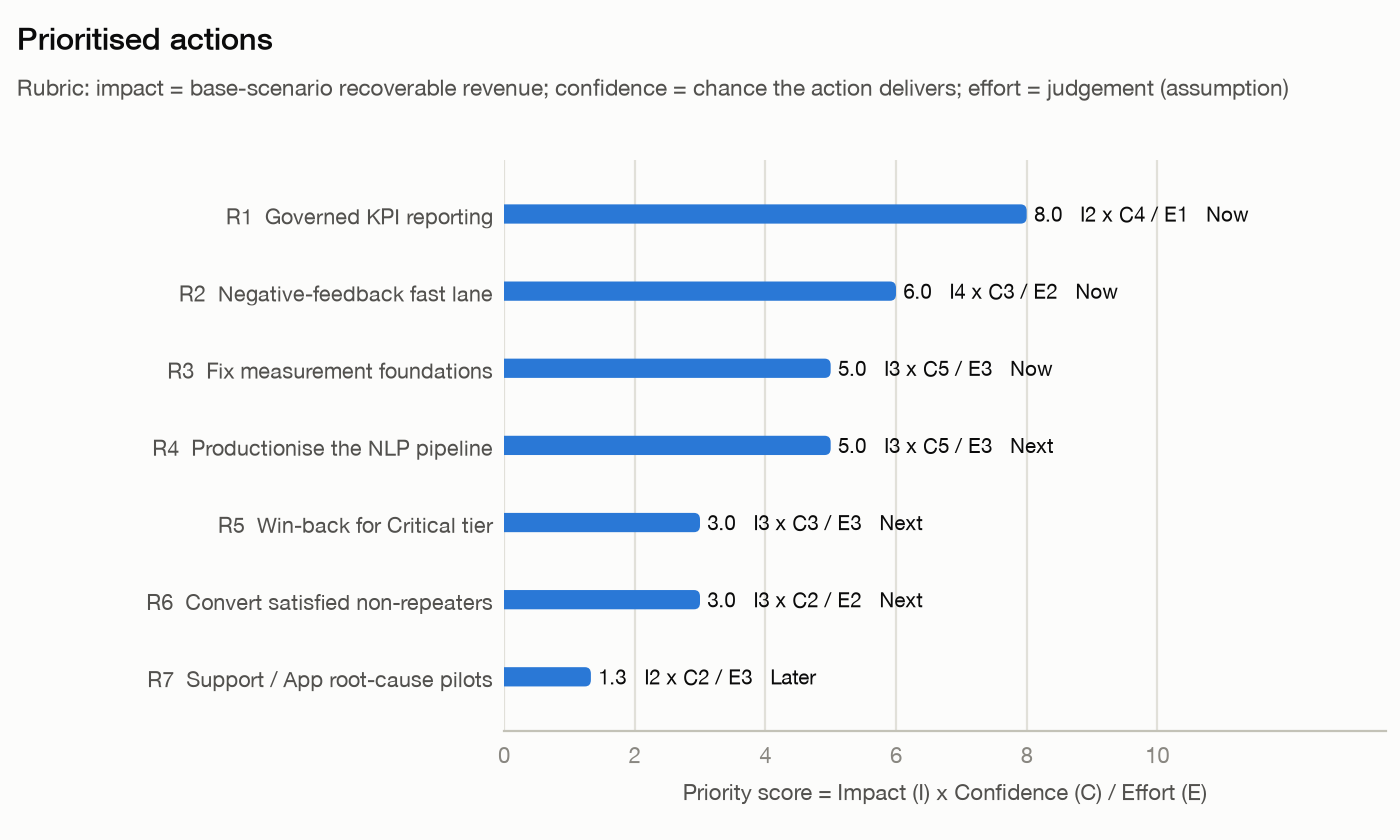

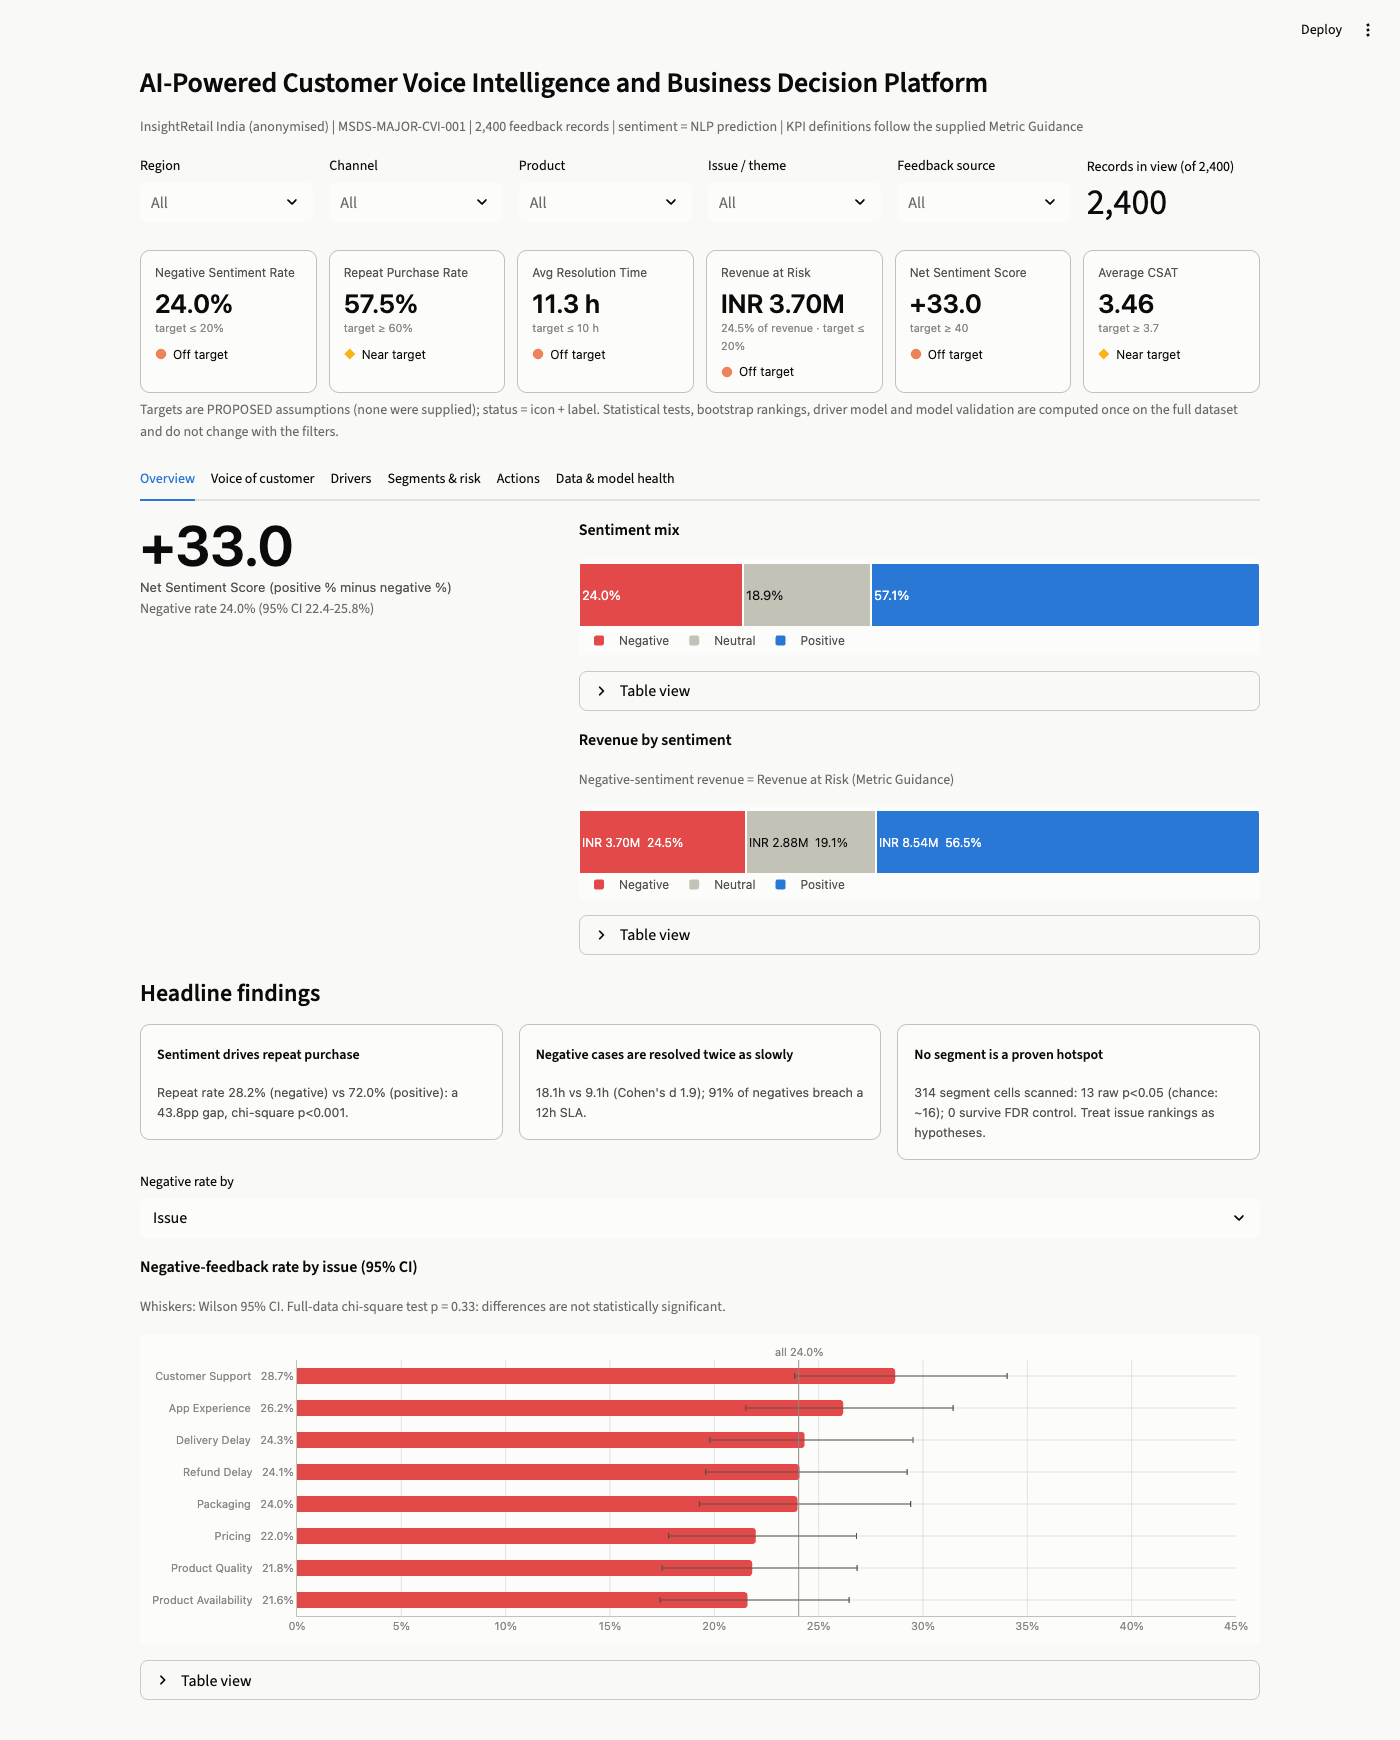

In [15]:
rec = table("decision_recommendations")
display(rec[["id", "phase", "type", "title", "impact_score", "confidence", "effort", "priority_score", "expected_impact"]])
fig("fig26_priority_ranking", 820)
display(Image(filename=str(C.ROOT / "dashboard" / "screenshots" / "streamlit_1_overview.png"), width=820))

## Activity 12 - Validation, documentation and final review
65 automated tests (written by the test run itself into the template's *Test Cases* layout), a run manifest and the limitations.

In [16]:
tests = pd.read_csv(C.VALIDATION_DIR / "test_results.csv")
print(len(tests), "tests |", tests["Pass / Fail"].value_counts().to_dict())
display(tests.groupby("Component")["Pass / Fail"].agg(tests="size", passed=lambda x: int((x == "Pass").sum())).reset_index())
man = json.load(open(C.OUT_DIR / "run_manifest.json"))
print("input sha256:", man["input"]["sha256"][:16], "... | seed", man["seed"], "| python", man["environment"]["python"], "| stages:", list(man["stage_seconds"]))
print("packages:", {k: v for k, v in man["environment"]["packages"].items() if k in ("pandas", "numpy", "scikit-learn", "sklearn", "scipy", "statsmodels", "plotly", "streamlit")})

65 tests | {'Pass': 65}


,Component,tests,passed
0,Data mining,5,5
1,Data quality,11,11
2,Decision layer,3,3
3,Ingestion,6,6
4,Integration,4,4
5,KPI,4,4
6,NLP pre-processing,6,6
7,Reproducibility,2,2
8,Sentiment,7,7
9,Topics,5,5


input sha256: 028d65da7b2e1d1d ... | seed 42 | python 3.13.9 | stages: ['warehouse', 'analytics_load', 'validate', 'ingest', 'transform', 'eda', 'sentiment', 'topics', 'mining', 'integrate', 'decision', 'figures']
packages: {'pandas': '2.3.3', 'numpy': '2.3.5', 'scipy': '1.16.3', 'sklearn': '1.9.1', 'statsmodels': '0.14.5', 'plotly': '6.3.0', 'streamlit': '1.51.0'}


**Limitations (consolidated):** templated text and rating-implied labels; no timestamps and no stable customer key; cross-sectional data, so impacts are scenarios not forecasts; no competitor data was supplied (the 'Competitor Alpha' workbook holds only the data dictionary and metric guidance); targets and effort scores are proposed assumptions; English-only NLP; single-node tooling.